In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(".")

watch_history = pd.read_csv(DATA_DIR / "dataset11-30.csv")

schedule_11_20 = pd.read_csv(DATA_DIR / "export_arh_11-20-final.csv")
schedule_21_30 = pd.read_csv(DATA_DIR / "export_arh_21-30-final.csv")
schedule_31_42 = pd.read_csv(DATA_DIR / "export_arh_31-42-final.csv")

submission = pd.read_csv(DATA_DIR / "submission.csv")

C:\Users\golom\AppData\Local\Temp\ipykernel_18772\1214658163.py:10: DtypeWarning: Columns (10: year_of_production) have mixed types. Specify dtype option on import or set low_memory=False.
  schedule_31_42 = pd.read_csv(DATA_DIR / "export_arh_31-42-final.csv")


In [2]:
datasets = {
    "watch_history": watch_history,
    "schedule_11_20": schedule_11_20,
    "schedule_21_30": schedule_21_30,
    "schedule_31_42": schedule_31_42,
    "submission": submission,
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name}: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(df.head(3).to_string(index=False))


watch_history: (5821987, 5)
Columns: ['user_id', 'vsetv_id', 'start_time', 'stop_time', 'duraton']
             user_id  vsetv_id          start_time           stop_time  duraton
 3398461054087191302         6 2020-03-09 00:00:02 2020-03-09 00:01:53      111
17226860011138219284       353 2020-03-09 00:00:02 2020-03-09 00:03:26      204
18417531283109304442       332 2020-03-09 00:00:05 2020-03-09 00:01:26       81

schedule_11_20: (1074235, 13)
Columns: ['channel_id', 'channel_title', 'start_time', 'duration', 'tv_show_title', 'tv_show_id', 'tv_show_category', 'tv_show_genre_1', 'tv_show_genre_2', 'tv_show_genre_3', 'year_of_production', 'director', 'actors']
 channel_id channel_title          start_time  duration                          tv_show_title  tv_show_id tv_show_category     tv_show_genre_1 tv_show_genre_2 tv_show_genre_3 year_of_production director actors
          3           1+1 09.03.2020 06:00:00      6000      'Жизнь известных людей', 2 сезон.           0           Др

In [3]:
watch_history.info()
schedule_11_20.info()
schedule_21_30.info()

<class 'pandas.DataFrame'>
RangeIndex: 5821987 entries, 0 to 5821986
Data columns (total 5 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   user_id     uint64
 1   vsetv_id    int64 
 2   start_time  str   
 3   stop_time   str   
 4   duraton     int64 
dtypes: int64(2), str(2), uint64(1)
memory usage: 433.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 1074235 entries, 0 to 1074234
Data columns (total 13 columns):
 #   Column              Non-Null Count    Dtype
---  ------              --------------    -----
 0   channel_id          1074235 non-null  int64
 1   channel_title       1074235 non-null  str  
 2   start_time          1074235 non-null  str  
 3   duration            1074235 non-null  int64
 4   tv_show_title       1074235 non-null  str  
 5   tv_show_id          1074235 non-null  int64
 6   tv_show_category    1074235 non-null  str  
 7   tv_show_genre_1     454146 non-null   str  
 8   tv_show_genre_2     146226 non-null   str  
 9   tv_show_genre_3     20176 

In [4]:
# Приводим названия столбцов к единому формату
watch_history = watch_history.rename(columns={
    "vsetv_id": "channel_id",
    "stop_time": "end_time",
    "duraton": "duration"
})

# Преобразуем даты просмотров
watch_history["start_time"] = pd.to_datetime(
    watch_history["start_time"],
    format="%Y-%m-%d %H:%M:%S"
)

watch_history["end_time"] = pd.to_datetime(
    watch_history["end_time"],
    format="%Y-%m-%d %H:%M:%S"
)

# Объединяем историческое расписание
schedule_train = pd.concat(
    [schedule_11_20, schedule_21_30],
    ignore_index=True
)

# Преобразуем даты расписания
for df in [schedule_train, schedule_31_42]:
    df["start_time"] = pd.to_datetime(
        df["start_time"],
        format="%d.%m.%Y %H:%M:%S"
    )

    df["end_time"] = (
        df["start_time"] +
        pd.to_timedelta(df["duration"], unit="s")
    )

# Удаляем нерелевантные передачи
schedule_train = schedule_train[
    (schedule_train["tv_show_id"] != 0) &
    (schedule_train["duration"] > 0)
].copy()

schedule_31_42 = schedule_31_42[
    (schedule_31_42["tv_show_id"] != 0) &
    (schedule_31_42["duration"] > 0)
].copy()

In [5]:
print("Unique users:", watch_history["user_id"].nunique())
print("Unique channels:", watch_history["channel_id"].nunique())
print("Unique historical shows:", schedule_train["tv_show_id"].nunique())
print("Unique future shows:", schedule_31_42["tv_show_id"].nunique())

print("\nWatch history range:")
print(watch_history["start_time"].min())
print(watch_history["end_time"].max())

print("\nSchedule train range:")
print(schedule_train["start_time"].min())
print(schedule_train["end_time"].max())

print("\nUsers in submission:")
print(submission["user_id"].nunique())

print("\nSubmission users present in history:")
print(
    submission["user_id"].isin(
        watch_history["user_id"]
    ).sum()
)

print("\nInvalid watch intervals:")
print(
    (watch_history["end_time"] <= watch_history["start_time"]).sum()
)

print("\nDuplicate schedule entries:")
print(
    schedule_train.duplicated(
        subset=["channel_id", "start_time", "duration", "tv_show_id"]
    ).sum()
)

Unique users: 4914
Unique channels: 202
Unique historical shows: 8234
Unique future shows: 6636

Watch history range:
2020-03-09 00:00:02
2020-07-26 23:59:58

Schedule train range:
2020-03-08 23:00:00
2020-07-27 08:15:00

Users in submission:
1260

Submission users present in history:
1260

Invalid watch intervals:
0

Duplicate schedule entries:
0


In [6]:
import duckdb

con = duckdb.connect()

con.register("watch_history", watch_history)
con.register("schedule_train", schedule_train)

matched_views = con.execute("""
    SELECT
        w.user_id,
        s.tv_show_id,
        w.channel_id,
        s.start_time AS show_start,
        s.end_time AS show_end,
        s.duration AS show_duration,

        GREATEST(w.start_time, s.start_time) AS overlap_start,
        LEAST(w.end_time, s.end_time) AS overlap_end

    FROM watch_history w
    JOIN schedule_train s
        ON w.channel_id = s.channel_id
        AND w.start_time < s.end_time
        AND w.end_time > s.start_time
""").df()

print("Matched intervals:", len(matched_views))
matched_views.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Matched intervals: 3847696


,user_id,tv_show_id,channel_id,show_start,show_end,show_duration,overlap_start,overlap_end
0,10444933497224964023,90042421,75,2020-03-22 15:45:00,2020-03-22 17:10:00,5100,2020-03-22 16:58:12,2020-03-22 17:00:46
1,3717325247828093568,90065205,317,2020-03-22 17:00:00,2020-03-22 18:30:00,5400,2020-03-22 17:00:46,2020-03-22 17:01:54
2,10444933497224964023,200469,460,2020-03-22 15:55:00,2020-03-22 21:00:00,18300,2020-03-22 17:01:30,2020-03-22 17:07:20
3,4051396765385629500,1000439,1002,2020-03-22 16:00:00,2020-03-22 19:30:00,12600,2020-03-22 16:41:34,2020-03-22 16:43:00
4,4051396765385629500,1000439,1002,2020-03-22 16:00:00,2020-03-22 19:30:00,12600,2020-03-22 16:43:07,2020-03-22 16:44:08


In [7]:
matched_views = matched_views.sort_values(
    ["user_id", "channel_id", "show_start", "show_end",
     "tv_show_id", "overlap_start", "overlap_end"]
).reset_index(drop=True)

keys = [
    "user_id", "channel_id", "show_start",
    "show_end", "tv_show_id"
]

group_start = matched_views[keys].ne(
    matched_views[keys].shift()
).any(axis=1)

previous_max_end = (
    matched_views.groupby(keys, sort=False)["overlap_end"]
    .cummax()
    .groupby(
        [matched_views[k] for k in keys],
        sort=False
    )
    .shift()
)

new_segment = (
    group_start |
    (matched_views["overlap_start"] > previous_max_end)
)

matched_views["segment_id"] = new_segment.cumsum()

segments = matched_views.groupby(
    ["segment_id", *keys],
    as_index=False
).agg(
    start=("overlap_start", "min"),
    end=("overlap_end", "max")
)

segments["watched_seconds"] = (
    segments["end"] - segments["start"]
).dt.total_seconds()

show_views = segments.groupby(
    keys, as_index=False
)["watched_seconds"].sum()

show_views["show_duration"] = (
    show_views["show_end"] - show_views["show_start"]
).dt.total_seconds()

show_views["screen_time_ratio"] = (
    show_views["watched_seconds"] /
    show_views["show_duration"]
)

In [8]:
qualified_views = show_views[
    show_views["screen_time_ratio"] >= 0.8
].copy()

print("Qualified show views:", len(qualified_views))
qualified_views.head()

Qualified show views: 611760


,user_id,channel_id,show_start,show_end,tv_show_id,watched_seconds,show_duration,screen_time_ratio
10,2244466330591177,5,2020-03-13 18:45:00,2020-03-13 19:25:00,240081,2400.0,2400.0,1.000000
16,2244466330591177,5,2020-03-17 18:45:00,2020-03-17 19:20:00,240081,2100.0,2100.0,1.000000
18,2244466330591177,5,2020-03-18 18:45:00,2020-03-18 19:25:00,240081,2344.0,2400.0,0.976667
33,2244466330591177,23,2020-03-16 10:30:00,2020-03-16 11:05:00,6200371,1986.0,2100.0,0.945714
44,2244466330591177,597,2020-07-24 19:48:00,2020-07-24 19:59:00,12002806,660.0,660.0,1.000000


In [9]:
interactions = (
    qualified_views
    .groupby(["user_id", "tv_show_id"])
    .size()
    .reset_index(name="watch_count")
)

interactions.head(10)

,user_id,tv_show_id,watch_count
0,2244466330591177,240081,3
1,2244466330591177,6200371,1
2,2244466330591177,10001261,2
3,2244466330591177,12001682,1
4,2244466330591177,12002107,3
5,2244466330591177,12002806,1
6,2244466330591177,12002856,2
7,3767274164463716,300375,1
8,3767274164463716,400387,1
9,3767274164463716,500331,2


In [10]:
import numpy as np
from scipy.sparse import csr_matrix

user_ids = np.sort(watch_history["user_id"].unique())
show_ids = np.sort(schedule_train["tv_show_id"].unique())

user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
show_to_idx = {show: idx for idx, show in enumerate(show_ids)}

rows = interactions["user_id"].map(user_to_idx).to_numpy()
cols = interactions["tv_show_id"].map(show_to_idx).to_numpy()
values = interactions["watch_count"].to_numpy()

R = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(show_ids)),
    dtype=np.float32
)

print("Matrix shape:", R.shape)
print("Non-zero interactions:", R.nnz)
print("Sparsity:", 1 - R.nnz / (R.shape[0] * R.shape[1]))

Matrix shape: (4914, 8234)
Non-zero interactions: 228575
Sparsity: 0.9943508551111174


In [11]:
print("Users with interactions:", (R.getnnz(axis=1) > 0).sum())
print("Shows with interactions:", (R.getnnz(axis=0) > 0).sum())
print("Total qualified views:", R.sum())

print("\nTop 10 most watched shows:")
display(
    interactions.groupby("tv_show_id")["watch_count"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Users with interactions: 4841
Shows with interactions: 3866
Total qualified views: 611760.0

Top 10 most watched shows:


tv_show_id
2400480     62451
12001682    45232
240081      45071
20088       21380
2400508     19264
2400467     15260
12002955    14173
12002856    12276
12001734    11111
12002805     9460
Name: watch_count, dtype: int64

In [12]:
interactions

,user_id,tv_show_id,watch_count
0,2244466330591177,240081,3
1,2244466330591177,6200371,1
2,2244466330591177,10001261,2
3,2244466330591177,12001682,1
4,2244466330591177,12002107,3
...,...,...,...
228570,18440717181607000261,90080816,1
228571,18440717181607000261,90082527,1
228572,18443832178892490378,240081,1
228573,18443832178892490378,10002245,2


In [13]:
R 

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 228575 stored elements and shape (4914, 8234)>

In [14]:
import numpy as np
import pandas as pd

views_per_user = np.asarray(R.sum(axis=1)).ravel()
shows_per_user = R.getnnz(axis=1)
users_per_show = R.getnnz(axis=0)

stats = pd.DataFrame({
    "qualified_views": views_per_user,
    "unique_shows": shows_per_user
})

display(stats.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

print("Users with 0 shows:", (shows_per_user == 0).sum())
print("Users with < 5 shows:", (shows_per_user < 5).sum())
print("Users with >= 5 shows:", (shows_per_user >= 5).sum())
print("Shows with 0 viewers:", (users_per_show == 0).sum())
print("Matrix density:", R.nnz / (R.shape[0] * R.shape[1]))

,qualified_views,unique_shows
count,4914.000000,4914.000000
mean,124.493286,46.515059
std,144.140884,46.409117
min,0.000000,0.000000
25%,32.000000,17.000000
50%,80.000000,32.000000
75%,167.000000,59.000000
90%,288.000000,105.000000
95%,387.000000,144.350000
99%,667.740000,218.870000


Users with 0 shows: 73
Users with < 5 shows: 281
Users with >= 5 shows: 4633
Shows with 0 viewers: 4368
Matrix density: 0.005649144888882562


In [15]:
submission_indices = [
    user_to_idx[u]
    for u in submission["user_id"]
]

submission_stats = stats.iloc[submission_indices]

display(submission_stats.describe())

print(
    "Submission users with < 5 shows:",
    (submission_stats["unique_shows"] < 5).sum()
)

print(
    "Submission users with 0 shows:",
    (submission_stats["unique_shows"] == 0).sum()
)

,qualified_views,unique_shows
count,1260.000000,1260.000000
mean,155.662704,55.146825
std,159.105515,48.960504
min,0.000000,0.000000
25%,53.000000,24.000000
50%,109.000000,40.000000
75%,202.000000,66.250000
max,1527.000000,329.000000


Submission users with < 5 shows: 19
Submission users with 0 shows: 4


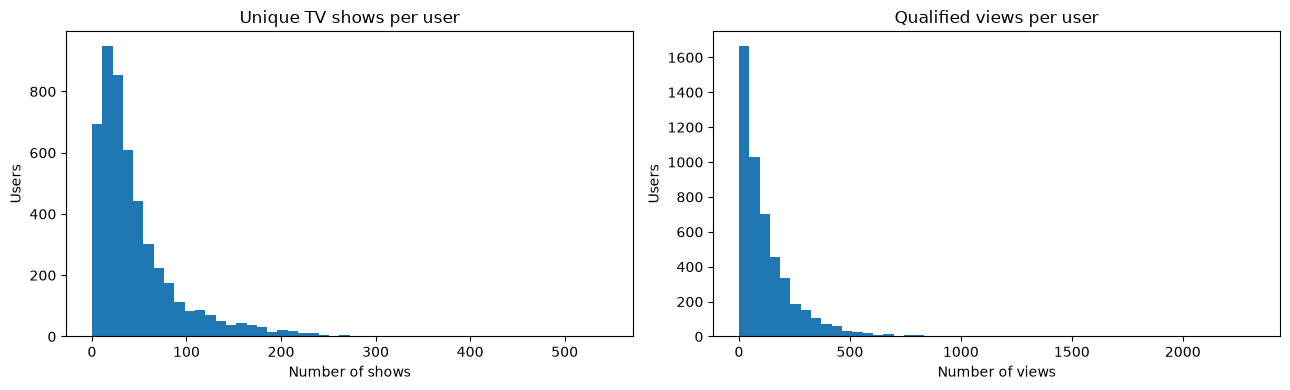

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(shows_per_user, bins=50)
axes[0].set_title("Unique TV shows per user")
axes[0].set_xlabel("Number of shows")
axes[0].set_ylabel("Users")

axes[1].hist(views_per_user, bins=50)
axes[1].set_title("Qualified views per user")
axes[1].set_xlabel("Number of views")
axes[1].set_ylabel("Users")

plt.tight_layout()
plt.show()

In [17]:
historical_shows = set(schedule_train["tv_show_id"])
future_shows = set(schedule_31_42["tv_show_id"])

common_shows = historical_shows & future_shows
new_shows = future_shows - historical_shows

print("Historical shows:", len(historical_shows))
print("Future shows:", len(future_shows))
print("Common shows:", len(common_shows))
print("New future shows:", len(new_shows))

print(
    "Future catalog overlap:",
    f"{len(common_shows) / len(future_shows):.2%}"
)

print(
    "Historical catalog retained:",
    f"{len(common_shows) / len(historical_shows):.2%}"
)

Historical shows: 8234
Future shows: 6636
Common shows: 5199
New future shows: 1437
Future catalog overlap: 78.35%
Historical catalog retained: 63.14%


In [18]:
future_mask = np.isin(show_ids, schedule_31_42["tv_show_id"].unique())

future_history_counts = R[:, future_mask].getnnz(axis=1)

submission_counts = future_history_counts[submission_indices]

print("Submission users with >= 5 known future shows:",
      (submission_counts >= 5).sum())

print("Submission users with < 5 known future shows:",
      (submission_counts < 5).sum())

print("Submission users with 0 known future shows:",
      (submission_counts == 0).sum())

print("\nDistribution:")
print(pd.Series(submission_counts).describe())

Submission users with >= 5 known future shows: 1238
Submission users with < 5 known future shows: 22
Submission users with 0 known future shows: 5

Distribution:
count    1260.000000
mean       48.465873
std        41.724441
min         0.000000
25%        22.000000
50%        36.000000
75%        58.000000
max       277.000000
dtype: float64


In [19]:
import numpy as np

future_shows = set(schedule_31_42["tv_show_id"].unique())

# Глобальная популярность для заполнения недостающих рекомендаций
global_popularity = np.asarray(R.sum(axis=0)).ravel()

popular_future_shows = [
    int(show_ids[i])
    for i in np.argsort(-global_popularity, kind="stable")
    if show_ids[i] in future_shows
]

# Добавляем новые передачи, отсутствующие в исторической матрице
popular_future_shows += sorted(future_shows - set(popular_future_shows))

def recommend_history(user_id, k=5):
    user_idx = user_to_idx[user_id]

    row = R.getrow(user_idx)

    candidates = [
        (int(show_ids[i]), float(score))
        for i, score in zip(row.indices, row.data)
        if show_ids[i] in future_shows
    ]

    candidates.sort(key=lambda x: (-x[1], x[0]))

    recommendations = [show for show, _ in candidates[:k]]

    # Fallback для пользователей с менее чем 5 кандидатами
    for show in popular_future_shows:
        if len(recommendations) >= k:
            break
        if show not in recommendations:
            recommendations.append(show)

    return recommendations

In [20]:
for user_id in submission["user_id"].head(5):
    print(user_id, recommend_history(user_id))

8377619604347126107 [2400480, 240081, 2400508, 12002955, 20088]
8381667675275833309 [2400480, 240081, 200344, 12001682, 500346]
8387147770138767246 [12001682, 12002856, 12001732, 12002955, 12002355]
8397181578236218580 [2400480, 20088, 240081, 6700482, 2400467]
8404698046253197367 [2400480, 240081, 20088, 10003012, 6200371]


In [21]:
baseline_submission = submission.copy()

baseline_submission["tv_show_id"] = [
    " ".join(map(str, recommend_history(user_id)))
    for user_id in baseline_submission["user_id"]
]

baseline_submission.to_csv(
    "submission_history_baseline.csv",
    index=False
)

baseline_submission.head()

,user_id,tv_show_id
0,8377619604347126107,2400480 240081 2400508 12002955 20088
1,8381667675275833309,2400480 240081 200344 12001682 500346
2,8387147770138767246,12001682 12002856 12001732 12002955 12002355
3,8397181578236218580,2400480 20088 240081 6700482 2400467
4,8404698046253197367,2400480 240081 20088 10003012 6200371


In [22]:
import numpy as np
import pandas as pd

VAL_START = pd.Timestamp("2020-05-18")
VAL_END = pd.Timestamp("2020-07-27")

train_views = qualified_views[
    qualified_views["show_start"] < VAL_START
].copy()

val_views = qualified_views[
    (qualified_views["show_start"] >= VAL_START) &
    (qualified_views["show_start"] < VAL_END)
].copy()

print("Train qualified views:", len(train_views))
print("Validation qualified views:", len(val_views))

Train qualified views: 316734
Validation qualified views: 295026


In [23]:
val_counts = (
    val_views
    .groupby(["user_id", "tv_show_id"])
    .size()
    .reset_index(name="watch_count")
)

val_counts = val_counts.sort_values(
    ["user_id", "watch_count", "tv_show_id"],
    ascending=[True, False, True]
)

val_top5 = (
    val_counts
    .groupby("user_id")
    .head(5)
)

ground_truth = (
    val_top5
    .groupby("user_id")["tv_show_id"]
    .apply(list)
    .to_dict()
)

# Условия соревнования: ровно 5 передач
ground_truth = {
    user: shows
    for user, shows in ground_truth.items()
    if len(shows) == 5
}

print("Validation users:", len(ground_truth))

Validation users: 4030


In [24]:
train_counts = (
    train_views
    .groupby(["user_id", "tv_show_id"])
    .size()
    .reset_index(name="watch_count")
)

# Какие передачи доступны в validation
val_catalog = set(
    schedule_21_30.loc[
        schedule_21_30["tv_show_id"] != 0,
        "tv_show_id"
    ]
)

# Исторические предпочтения пользователей
user_history = {}

for user_id, group in train_counts.groupby("user_id"):
    group = group.sort_values(
        ["watch_count", "tv_show_id"],
        ascending=[False, True]
    )

    user_history[user_id] = [
        int(show)
        for show in group["tv_show_id"]
        if show in val_catalog
    ]

In [25]:
global_popularity = (
    train_counts
    .groupby("tv_show_id")["watch_count"]
    .sum()
    .sort_values(ascending=False)
)

popular_shows = [
    int(show)
    for show in global_popularity.index
    if show in val_catalog
]

# Заполняем каталог, если популярных передач недостаточно
popular_shows += sorted(val_catalog - set(popular_shows))

def recommend_popularity(user_id, k=5):
    return popular_shows[:k]

In [26]:
def recommend_history_val(user_id, k=5):
    recommendations = user_history.get(user_id, [])[:k]

    for show in popular_shows:
        if len(recommendations) >= k:
            break

        if show not in recommendations:
            recommendations.append(show)

    return recommendations

In [27]:
def recall_at_5(predicted, actual):
    return len(set(predicted) & set(actual)) / 5


def ndcg_at_5(predicted, actual):
    actual_set = set(actual)

    dcg = sum(
        1 / np.log2(rank + 2)
        for rank, show in enumerate(predicted[:5])
        if show in actual_set
    )

    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(5)
    )

    return dcg / idcg


def evaluate(recommender, ground_truth):
    recalls = []
    ndcgs = []

    for user_id, actual in ground_truth.items():
        predicted = recommender(user_id)

        recalls.append(recall_at_5(predicted, actual))
        ndcgs.append(ndcg_at_5(predicted, actual))

    return {
        "Recall@5": np.mean(recalls),
        "NDCG@5": np.mean(ndcgs),
    }


results = pd.DataFrame({
    "Popularity": evaluate(recommend_popularity, ground_truth),
    "User History": evaluate(recommend_history_val, ground_truth),
}).T

display(results)

,Recall@5,NDCG@5
Popularity,0.357667,0.404052
User History,0.409727,0.470986


In [28]:
overlaps = []

for user_id, actual in ground_truth.items():
    historical = set(user_history.get(user_id, []))
    overlaps.append(len(historical & set(actual)) / 5)

print("Historical candidate Recall@5 upper bound:",
      np.mean(overlaps))

Historical candidate Recall@5 upper bound: 0.5619354838709677


Shows: 6363
Example: [(20088, 250), (30066, 12), (30085, 119), (52641, 1), (90054, 1)]


,alpha,Recall@5,NDCG@5
0,0.00,0.409727,0.470986
1,0.10,0.417221,0.479418
2,0.25,0.420347,0.482409
3,0.50,0.421439,0.481134
4,0.75,0.414094,0.471339
5,1.00,0.408189,0.462126
6,1.50,0.396725,0.445313
7,2.00,0.389380,0.433955


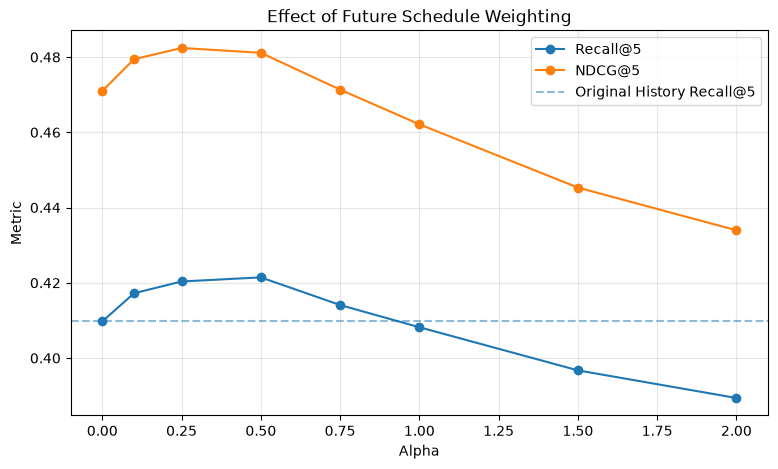

In [31]:
future_show_counts = (
    schedule_21_30[
        schedule_21_30["tv_show_id"] != 0
    ]
    .groupby("tv_show_id")
    .size()
    .to_dict()
)

print("Shows:", len(future_show_counts))
print("Example:", list(future_show_counts.items())[:5])

# Исторические частоты просмотров каждого пользователя
user_watch_counts = {
    user_id: dict(zip(group["tv_show_id"], group["watch_count"]))
    for user_id, group in train_counts.groupby("user_id")
}

def recommend_schedule_weighted(user_id, alpha=0.5, k=5):
    history = user_watch_counts.get(user_id, {})

    candidates = []

    for show_id, watch_count in history.items():
        if show_id not in val_catalog:
            continue

        n_future = future_show_counts.get(show_id, 0)

        score = watch_count * (1 + n_future) ** alpha

        candidates.append((int(show_id), score))

    candidates.sort(key=lambda x: (-x[1], x[0]))

    recommendations = [show for show, _ in candidates[:k]]

    # Тот же popularity fallback, что и раньше
    for show in popular_shows:
        if len(recommendations) >= k:
            break

        if show not in recommendations:
            recommendations.append(show)

    return recommendations

alphas = [0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]

results_schedule = []

for alpha in alphas:
    metrics = evaluate(
        lambda user_id: recommend_schedule_weighted(
            user_id, alpha=alpha
        ),
        ground_truth
    )

    results_schedule.append({
        "alpha": alpha,
        **metrics
    })

results_schedule = pd.DataFrame(results_schedule)

display(results_schedule)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    results_schedule["alpha"],
    results_schedule["Recall@5"],
    marker="o",
    label="Recall@5"
)

plt.plot(
    results_schedule["alpha"],
    results_schedule["NDCG@5"],
    marker="o",
    label="NDCG@5"
)

plt.axhline(
    0.409727,
    linestyle="--",
    alpha=0.5,
    label="Original History Recall@5"
)

plt.xlabel("Alpha")
plt.ylabel("Metric")
plt.title("Effect of Future Schedule Weighting")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:

import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIG
# ============================================================

VAL_START = pd.Timestamp("2020-05-18")
VAL_END = pd.Timestamp("2020-07-27")

ALPHAS = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
BETAS = [0, 0.25, 0.5, 1.0, 1.5, 2.0]

K = 5
SMOOTHING = 0.2

# ============================================================
# 2. DATETIME PREPARATION
# ============================================================

watch_history["start_time"] = pd.to_datetime(
    watch_history["start_time"],
    errors="coerce"
)

watch_history["end_time"] = pd.to_datetime(
    watch_history["end_time"],
    errors="coerce"
)

schedule_21_30["start_time"] = pd.to_datetime(
    schedule_21_30["start_time"],
    dayfirst=True,
    errors="coerce"
)

# ============================================================
# 3. MAP@5
# ============================================================

def ap_at_5(predicted, actual):
    relevant = set(actual)
    hits = 0
    score = 0.0
    seen = set()

    for rank, show in enumerate(predicted[:5], start=1):
        if show in relevant and show not in seen:
            hits += 1
            score += hits / rank
        seen.add(show)

    return score / min(5, len(relevant))


def map_at_5(predictions, truth):
    return float(np.mean([
        ap_at_5(predictions[u], truth[u])
        for u in truth
    ]))


# ============================================================
# 4. USER ACTIVITY BY HOUR OF WEEK
# ============================================================

history_sessions = watch_history.loc[
    (watch_history["start_time"] < VAL_START) &
    (watch_history["end_time"] > watch_history["start_time"]),
    ["user_id", "start_time", "end_time"]
].copy()

history_sessions["end_time"] = (
    history_sessions["end_time"].clip(upper=VAL_START)
)

history_sessions["slot"] = (
    history_sessions["start_time"].dt.dayofweek * 24
    + history_sessions["start_time"].dt.hour
)

history_sessions["seconds"] = (
    history_sessions["end_time"] -
    history_sessions["start_time"]
).dt.total_seconds()

activity_table = (
    history_sessions
    .groupby(["user_id", "slot"])["seconds"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=range(168), fill_value=0)
)

# Global distribution weighted by viewing duration
global_activity = activity_table.sum(axis=0).to_numpy(dtype=float, copy=True)
global_activity = global_activity / max(global_activity.sum(), 1)

# Per-user distribution with global smoothing
user_totals = activity_table.sum(axis=1)

activity_table = activity_table.div(
    user_totals.replace(0, 1),
    axis=0
)

activity_table = (
    (1 - SMOOTHING) * activity_table
    + SMOOTHING * global_activity
)

user_activity = {
    user_id: row
    for user_id, row in zip(
        activity_table.index,
        activity_table.to_numpy()
    )
}

print("User activity profiles:", len(user_activity))

# ============================================================
# 5. FUTURE SCHEDULE FEATURES
# ============================================================

future_schedule = schedule_21_30.loc[
    (schedule_21_30["tv_show_id"] != 0) &
    (schedule_21_30["duration"] > 0) &
    (schedule_21_30["start_time"] >= VAL_START) &
    (schedule_21_30["start_time"] < VAL_END)
].copy()

future_schedule["slot"] = (
    future_schedule["start_time"].dt.dayofweek * 24
    + future_schedule["start_time"].dt.hour
)

future_counts = (
    future_schedule.groupby("tv_show_id")
    .size()
    .to_dict()
)

show_slot_table = (
    future_schedule
    .groupby(["tv_show_id", "slot"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(168), fill_value=0)
)

show_slot_table = show_slot_table.div(
    show_slot_table.sum(axis=1),
    axis=0
)

show_ids_future = show_slot_table.index.to_numpy()
show_slot_matrix = show_slot_table.to_numpy(dtype=float)

show_to_future_idx = {
    show_id: idx
    for idx, show_id in enumerate(show_ids_future)
}

print("Future shows:", len(show_ids_future))

# ============================================================
# 6. HISTORICAL INTERACTIONS
# ============================================================

user_watch_counts = {
    user_id: dict(zip(
        group["tv_show_id"],
        group["watch_count"]
    ))
    for user_id, group in train_counts.groupby("user_id")
}

validation_users = list(ground_truth.keys())

# ============================================================
# 7. PRECOMPUTE TIME COMPATIBILITY
# ============================================================

# Matrix multiplication instead of Python loops over broadcasts
activity_matrix = np.vstack([
    user_activity.get(u, global_activity)
    for u in validation_users
])

compatibility_matrix = activity_matrix @ show_slot_matrix.T

user_to_val_idx = {
    u: idx for idx, u in enumerate(validation_users)
}

# ============================================================
# 8. RECOMMENDATION
# ============================================================

future_catalog = set(show_ids_future)

# Ensure fallback is also restricted to actual future shows
fallback_shows = [
    int(s) for s in popular_shows
    if s in future_catalog
]

fallback_shows += [
    int(s) for s in show_ids_future
    if s not in set(fallback_shows)
]

def recommend(user_id, alpha=0.0, beta=0.0, k=5):
    history = user_watch_counts.get(user_id, {})
    user_idx = user_to_val_idx[user_id]

    candidates = []

    for show_id, count in history.items():
        show_idx = show_to_future_idx.get(show_id)

        if show_idx is None:
            continue

        n = future_counts[show_id]
        p = compatibility_matrix[user_idx, show_idx]

        score = (
            count *
            (1 + n) ** alpha *
            (1 + p) ** beta
        )

        candidates.append((int(show_id), score))

    candidates.sort(key=lambda x: (-x[1], x[0]))

    recommendations = [s for s, _ in candidates[:k]]
    selected = set(recommendations)

    for show_id in fallback_shows:
        if len(recommendations) >= k:
            break

        if show_id not in selected:
            recommendations.append(show_id)
            selected.add(show_id)

    return recommendations


# ============================================================
# 9. EVALUATION
# ============================================================

results = []

# Global Popularity
pop_predictions = {
    u: fallback_shows[:K]
    for u in validation_users
}

results.append({
    "model": "Global Popularity",
    "alpha": 0.0,
    "beta": 0.0,
    "MAP@5": map_at_5(pop_predictions, ground_truth)
})

# History + Schedule + Time grid
for alpha in ALPHAS:
    for beta in BETAS:

        predictions = {
            u: recommend(u, alpha=alpha, beta=beta, k=K)
            for u in validation_users
        }

        score = map_at_5(predictions, ground_truth)

        if alpha == 0 and beta == 0:
            model = "User History"
        elif beta == 0:
            model = "History + Schedule"
        elif alpha == 0:
            model = "History + Time"
        else:
            model = "History + Schedule + Time"

        results.append({
            "model": model,
            "alpha": alpha,
            "beta": beta,
            "MAP@5": score
        })

results_df = pd.DataFrame(results)

# ============================================================
# 10. RESULTS
# ============================================================

print("\nBEST CONFIGURATION PER MODEL")

best_models = (
    results_df
    .sort_values("MAP@5", ascending=False)
    .drop_duplicates("model")
    .sort_values("MAP@5", ascending=False)
    .reset_index(drop=True)
)

display(best_models)

print("\nTOP 15 CONFIGURATIONS")

display(
    results_df
    .sort_values("MAP@5", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nMAP@5 GRID (alpha x beta)")

display(
    results_df[
        results_df["model"] != "Global Popularity"
    ]
    .pivot(index="alpha", columns="beta", values="MAP@5")
    .round(5)
)


User activity profiles: 4876
Future shows: 6361

BEST CONFIGURATION PER MODEL


,model,alpha,beta,MAP@5
0,History + Schedule + Time,0.25,0.25,0.359069
1,History + Schedule,0.25,0.00,0.359027
2,User History,0.00,0.00,0.346917
3,History + Time,0.00,0.25,0.336535
4,Global Popularity,0.00,0.00,0.279391



TOP 15 CONFIGURATIONS


,model,alpha,beta,MAP@5
0,History + Schedule + Time,0.25,0.25,0.359069
1,History + Schedule + Time,0.25,0.50,0.359067
2,History + Schedule + Time,0.25,1.50,0.359032
3,History + Schedule,0.25,0.00,0.359027
4,History + Schedule + Time,0.25,1.00,0.358992
5,History + Schedule + Time,0.25,2.00,0.358948
6,History + Schedule + Time,0.50,2.00,0.356658
7,History + Schedule + Time,0.50,1.50,0.356625
8,History + Schedule,0.50,0.00,0.356596
9,History + Schedule + Time,0.50,1.00,0.356585



MAP@5 GRID (alpha x beta)


beta,0.00,0.25,0.50,1.00,1.50,2.00
alpha,,,,,,
0.00,0.34692,0.33654,0.33654,0.33654,0.33654,0.33654
0.10,0.35562,0.35567,0.35571,0.35571,0.35565,0.35567
0.25,0.35903,0.35907,0.35907,0.35899,0.35903,0.35895
0.50,0.35660,0.35658,0.35658,0.35658,0.35663,0.35666
0.75,0.34622,0.34625,0.34625,0.34631,0.34629,0.34632
1.00,0.33698,0.33705,0.33708,0.33708,0.33717,0.33723


In [35]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

# ============================================================
# 1. CONFIG
# ============================================================

K_NEIGHBORS = 50
ALPHAS = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
TOP_K = 5

# ============================================================
# 2. BUILD TRAIN INTERACTION MATRIX
# ============================================================

cf_users = np.sort(train_counts["user_id"].unique())
cf_shows = np.sort(train_counts["tv_show_id"].unique())

user_to_cf_idx = {u: i for i, u in enumerate(cf_users)}
show_to_cf_idx = {s: i for i, s in enumerate(cf_shows)}

rows = train_counts["user_id"].map(user_to_cf_idx).to_numpy()
cols = train_counts["tv_show_id"].map(show_to_cf_idx).to_numpy()
values = train_counts["watch_count"].to_numpy(dtype=np.float32)

R_cf = csr_matrix(
    (values, (rows, cols)),
    shape=(len(cf_users), len(cf_shows)),
    dtype=np.float32
)

# ============================================================
# 3. ITEM-ITEM COSINE SIMILARITY
# ============================================================

# Binary interactions for similarity:
# similarity measures overlap of audiences,
# not the magnitude of repeated views.

R_binary = R_cf.copy()
R_binary.data[:] = 1.0

item_matrix = normalize(R_binary.T.tocsr(), norm="l2", axis=1)

# Sparse item-item similarity
S = (item_matrix @ item_matrix.T).tocsr()

# Remove self-similarity
S.setdiag(0)
S.eliminate_zeros()

# Keep only top-K neighbors for each item
S_topk = S.tolil()

for i in range(S.shape[0]):
    data = np.asarray(S_topk.data[i])
    cols = np.asarray(S_topk.rows[i])

    if len(data) > K_NEIGHBORS:
        top = np.argpartition(data, -K_NEIGHBORS)[-K_NEIGHBORS:]
        S_topk.data[i] = data[top].tolist()
        S_topk.rows[i] = cols[top].tolist()

S_topk = S_topk.tocsr()

# ============================================================
# 4. USER-ITEM CF SCORES
# ============================================================

# Historical watch counts × item similarity
CF_scores = (R_cf @ S_topk).tocsr()

# Do not recommend already-watched items?
# For this competition, repeats ARE allowed and useful.
# Therefore, we do NOT filter watched items.

# ============================================================
# 5. MAP@5
# ============================================================

def ap_at_5(predicted, actual):
    relevant = set(actual)
    hits = 0
    score = 0.0

    for rank, show in enumerate(predicted[:5], start=1):
        if show in relevant:
            hits += 1
            score += hits / rank

    return score / 5


def map_at_5(predictions, truth):
    return float(np.mean([
        ap_at_5(predictions[u], truth[u])
        for u in truth
    ]))

# ============================================================
# 6. RECOMMENDATIONS + EVALUATION
# ============================================================

# Candidate catalog is limited to future broadcasts
catalog_indices = np.array([
    show_to_cf_idx[s]
    for s in future_catalog
    if s in show_to_cf_idx
], dtype=np.int64)

catalog_shows = cf_shows[catalog_indices]

future_multipliers = np.array([
    1 + future_counts.get(s, 0)
    for s in catalog_shows
], dtype=np.float32)

results_cf = []

for alpha in ALPHAS:
    predictions = {}

    weights = future_multipliers ** alpha

    for user_id in ground_truth:
        user_idx = user_to_cf_idx.get(user_id)

        if user_idx is None:
            recommendations = []
        else:
            scores = CF_scores[user_idx, catalog_indices].toarray().ravel()
            scores = scores * weights

            # Rank only positive-score candidates.
            order = np.argsort(-scores, kind="stable")
            recommendations = [
                int(catalog_shows[j])
                for j in order
                if scores[j] > 0
            ][:TOP_K]

        # Popularity fallback for missing candidates
        selected = set(recommendations)

        for show_id in fallback_shows:
            if len(recommendations) >= TOP_K:
                break
            if show_id not in selected:
                recommendations.append(int(show_id))
                selected.add(show_id)

        predictions[user_id] = recommendations

    score = map_at_5(predictions, ground_truth)

    results_cf.append({
        "model": "Item-based CF",
        "neighbors": K_NEIGHBORS,
        "alpha": alpha,
        "MAP@5": score
    })

# ============================================================
# 7. RESULTS
# ============================================================

results_cf = pd.DataFrame(results_cf)

display(results_cf.sort_values("MAP@5", ascending=False))

print("Best CF MAP@5:", results_cf["MAP@5"].max())
print("History + Schedule baseline MAP@5: 0.359027")

,model,neighbors,alpha,MAP@5
1,Item-based CF,50,0.10,0.206023
2,Item-based CF,50,0.25,0.192458
3,Item-based CF,50,0.50,0.169786
0,Item-based CF,50,0.00,0.151071
4,Item-based CF,50,0.75,0.149052
5,Item-based CF,50,1.00,0.131527


Best CF MAP@5: 0.20602315963606285
History + Schedule baseline MAP@5: 0.359027


In [37]:
import numpy as np
import pandas as pd

# ============================================================
# HISTORY + ITEM-BASED CF + FUTURE SCHEDULE
# ============================================================

LAMBDAS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
ALPHAS = [0.0, 0.1, 0.25, 0.5]
TOP_K = 5

# Use exactly the validation-period future catalog
catalog_shows = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)

catalog_indices = np.array(
    [show_to_cf_idx[s] for s in catalog_shows],
    dtype=np.int64
)

schedule_weights = np.array(
    [1 + future_counts[s] for s in catalog_shows],
    dtype=np.float32
)

# Prepare matrices once, not inside the parameter grid
validation_users = list(ground_truth)

history_matrix = np.zeros(
    (len(validation_users), len(catalog_shows)),
    dtype=np.float32
)

cf_matrix = np.zeros_like(history_matrix)

for row, user_id in enumerate(validation_users):
    user_idx = user_to_cf_idx.get(user_id)

    if user_idx is None:
        continue

    history_matrix[row] = (
        R_cf[user_idx, catalog_indices].toarray().ravel()
    )

    cf_matrix[row] = (
        CF_scores[user_idx, catalog_indices].toarray().ravel()
    )

# Normalize each user's scores independently
history_matrix /= np.maximum(
    history_matrix.max(axis=1, keepdims=True), 1e-12
)

cf_matrix /= np.maximum(
    cf_matrix.max(axis=1, keepdims=True), 1e-12
)

# Popularity fallback, restricted to validation catalog
catalog_set = set(catalog_shows)

fallback = [
    int(s) for s in fallback_shows
    if s in catalog_set
]

fallback += [
    int(s) for s in catalog_shows
    if s not in set(fallback)
]

def evaluate_hybrid(lam, alpha):
    combined = (
        (1 - lam) * history_matrix
        + lam * cf_matrix
    )

    combined = combined * schedule_weights[None, :] ** alpha

    predictions = {}

    for row, user_id in enumerate(validation_users):
        scores = combined[row]

        # Only positive-score candidates
        order = np.argsort(-scores, kind="stable")

        recs = [
            int(catalog_shows[j])
            for j in order
            if scores[j] > 0
        ][:TOP_K]

        selected = set(recs)

        for show_id in fallback:
            if len(recs) >= TOP_K:
                break
            if show_id not in selected:
                recs.append(show_id)
                selected.add(show_id)

        predictions[user_id] = recs

    return map_at_5(predictions, ground_truth)


results_hybrid = []

for lam in LAMBDAS:
    for alpha in ALPHAS:
        score = evaluate_hybrid(lam, alpha)

        results_hybrid.append({
            "lambda": lam,
            "alpha": alpha,
            "MAP@5": score
        })

results_hybrid = pd.DataFrame(results_hybrid)

print("TOP 15 CONFIGURATIONS")
display(
    results_hybrid
    .sort_values("MAP@5", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nMAP@5: lambda × alpha")
display(
    results_hybrid.pivot(
        index="lambda",
        columns="alpha",
        values="MAP@5"
    ).round(5)
)

best = results_hybrid.loc[
    results_hybrid["MAP@5"].idxmax()
]

print(
    f"\nBest hybrid MAP@5: {best['MAP@5']:.6f}"
    f"\nBest lambda: {best['lambda']}"
    f"\nBest alpha: {best['alpha']}"
    f"\nPrevious baseline: 0.359027"
)

TOP 15 CONFIGURATIONS


,lambda,alpha,MAP@5
0,0.30,0.10,0.366347
1,0.20,0.10,0.365544
2,0.50,0.10,0.364248
3,0.10,0.10,0.363480
4,0.05,0.25,0.361452
5,0.10,0.25,0.361141
6,0.05,0.10,0.359955
7,0.00,0.25,0.359027
8,0.20,0.25,0.357424
9,0.00,0.50,0.356596



MAP@5: lambda × alpha


alpha,0.00,0.10,0.25,0.50
lambda,,,,
0.00,0.34692,0.35562,0.35903,0.35660
0.05,0.35326,0.35996,0.36145,0.35103
0.10,0.35404,0.36348,0.36114,0.34337
0.20,0.35552,0.36554,0.35742,0.32576
0.30,0.35483,0.36635,0.35146,0.30752
0.50,0.35407,0.36425,0.32701,0.25821
0.75,0.27568,0.31257,0.26605,0.20532
1.00,0.15107,0.20602,0.19246,0.16979



Best hybrid MAP@5: 0.366347
Best lambda: 0.3
Best alpha: 0.1
Previous baseline: 0.359027


In [39]:
%pip install implicit

   ---------------------------------------- 0.0/676.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/676.7 kB ? eta -:--:--
   ---------------------------------------- 0.0/676.7 kB ? eta -:--:--
   --------------- ------------------------ 262.1/676.7 kB ? eta -:--:--
   ---------------------------------------- 676.7/676.7 kB 1.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [40]:
import numpy as np
import pandas as pd
from implicit.als import AlternatingLeastSquares

# ============================================================
# 1. CONFIG
# ============================================================

FACTORS = 64
REGULARIZATION = 0.1
ITERATIONS = 30
CONFIDENCE_ALPHA = 20.0
SEED = 42

SCHEDULE_ALPHAS = [0.0, 0.1, 0.25, 0.5]
TOP_K = 5

# ============================================================
# 2. TRAIN IMPLICIT ALS
# ============================================================

# R_cf: users x shows, built ONLY from weeks 11–20
# Use confidence c_ui = 1 + alpha * watch_count.
# implicit expects alpha * watch_count as nonzero input;
# the baseline confidence of 1 is handled internally.

als_train = R_cf.copy().astype(np.float32)
als_train.data *= CONFIDENCE_ALPHA

als_model = AlternatingLeastSquares(
    factors=FACTORS,
    regularization=REGULARIZATION,
    iterations=ITERATIONS,
    random_state=SEED,
    num_threads=0
)

als_model.fit(als_train)

print("ALS training completed")
print("User factors:", als_model.user_factors.shape)
print("Item factors:", als_model.item_factors.shape)

# ============================================================
# 3. PREDICT SCORES FOR VALIDATION USERS
# ============================================================

validation_users = list(ground_truth)

# Future schedule catalog, restricted to items known to ALS
catalog_shows_als = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)

catalog_indices_als = np.array(
    [show_to_cf_idx[s] for s in catalog_shows_als],
    dtype=np.int64
)

schedule_weights_als = np.array(
    [1 + future_counts[s] for s in catalog_shows_als],
    dtype=np.float32
)

als_scores = np.zeros(
    (len(validation_users), len(catalog_shows_als)),
    dtype=np.float32
)

known_rows = []
known_user_indices = []

for row, user_id in enumerate(validation_users):
    user_idx = user_to_cf_idx.get(user_id)
    if user_idx is not None:
        known_rows.append(row)
        known_user_indices.append(user_idx)

if known_rows:
    als_scores[known_rows] = (
        als_model.user_factors[known_user_indices]
        @ als_model.item_factors[catalog_indices_als].T
    )

# ============================================================
# 4. MAP@5 EVALUATION
# ============================================================

als_catalog_set = set(catalog_shows_als)

# Include future-only shows in fallback even though ALS
# cannot score them directly
als_fallback = list(dict.fromkeys(
    [int(s) for s in fallback_shows]
    if "fallback_shows" in globals() else []
))

def recommend_als(row, alpha=0.0):
    scores = als_scores[row].copy()

    # ALS scores may be negative: only use positive preferences
    scores = np.maximum(scores, 0)

    scores *= schedule_weights_als ** alpha

    order = np.argsort(-scores, kind="stable")

    recs = [
        int(catalog_shows_als[j])
        for j in order
        if scores[j] > 0
    ][:TOP_K]

    selected = set(recs)

    for show_id in als_fallback:
        if len(recs) >= TOP_K:
            break

        if show_id not in selected:
            recs.append(show_id)
            selected.add(show_id)

    return recs


results_als = []

for alpha in SCHEDULE_ALPHAS:
    predictions = {
        user_id: recommend_als(row, alpha)
        for row, user_id in enumerate(validation_users)
    }

    score = map_at_5(predictions, ground_truth)

    results_als.append({
        "model": "Implicit ALS",
        "factors": FACTORS,
        "regularization": REGULARIZATION,
        "iterations": ITERATIONS,
        "confidence_alpha": CONFIDENCE_ALPHA,
        "schedule_alpha": alpha,
        "MAP@5": score
    })

results_als = pd.DataFrame(results_als)

print("\nALS RESULTS")
display(
    results_als
    .sort_values("MAP@5", ascending=False)
    .reset_index(drop=True)
)

print(f"\nBest ALS MAP@5: {results_als['MAP@5'].max():.6f}")
print("Best History + CF + Schedule MAP@5: 0.366347")

C:\Users\golom\anaconda3\envs\torchenv\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 24 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/30 [00:00<?, ?it/s]

ALS training completed
User factors: (4737, 64)
Item factors: (2499, 64)

ALS RESULTS


,model,factors,regularization,iterations,confidence_alpha,schedule_alpha,MAP@5
0,Implicit ALS,64,0.1,30,20.0,0.10,0.260887
1,Implicit ALS,64,0.1,30,20.0,0.25,0.245890
2,Implicit ALS,64,0.1,30,20.0,0.50,0.211026
3,Implicit ALS,64,0.1,30,20.0,0.00,0.161800



Best ALS MAP@5: 0.260887
Best History + CF + Schedule MAP@5: 0.366347


In [41]:
import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIG
# ============================================================

CF_WEIGHTS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
ALS_WEIGHTS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.4]

SCHEDULE_ALPHA = 0.1
TOP_K = 5

# ============================================================
# 2. COMMON CATALOG AND VALIDATION USERS
# ============================================================

validation_users = list(ground_truth.keys())

# Use the same candidate catalog as the earlier hybrid.
# ALS can only score shows known during training.
# Unknown ALS shows receive zero ALS score, but can still
# receive History / CF scores.

catalog_shows = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)

catalog_indices = np.array(
    [show_to_cf_idx[s] for s in catalog_shows],
    dtype=np.int64
)

n_users = len(validation_users)
n_items = len(catalog_shows)

# ============================================================
# 3. HISTORY AND CF SCORES
# ============================================================

history_scores = np.zeros((n_users, n_items), dtype=np.float32)
cf_scores = np.zeros((n_users, n_items), dtype=np.float32)
als_scores_hybrid = np.zeros((n_users, n_items), dtype=np.float32)

for row, user_id in enumerate(validation_users):
    user_idx = user_to_cf_idx.get(user_id)

    if user_idx is None:
        continue

    history_scores[row] = (
        R_cf[user_idx, catalog_indices].toarray().ravel()
    )

    cf_scores[row] = (
        CF_scores[user_idx, catalog_indices].toarray().ravel()
    )

    # ALS uses the same user/item index mappings as R_cf
    als_scores_hybrid[row] = (
        als_model.user_factors[user_idx]
        @ als_model.item_factors[catalog_indices].T
    )

# ============================================================
# 4. NORMALIZATION
# ============================================================

def normalize_scores(matrix):
    matrix = np.maximum(matrix, 0)

    maximums = matrix.max(axis=1, keepdims=True)

    return matrix / np.maximum(maximums, 1e-12)


history_norm = normalize_scores(history_scores)
cf_norm = normalize_scores(cf_scores)
als_norm = normalize_scores(als_scores_hybrid)

# ============================================================
# 5. SCHEDULE WEIGHTS
# ============================================================

schedule_weights = np.array(
    [
        (1 + future_counts[s]) ** SCHEDULE_ALPHA
        for s in catalog_shows
    ],
    dtype=np.float32
)

catalog_set = set(catalog_shows)

fallback = list(dict.fromkeys(
    int(s) for s in fallback_shows
    if s in catalog_set
))

fallback += [
    int(s) for s in catalog_shows
    if s not in set(fallback)
]

# ============================================================
# 6. EVALUATION
# ============================================================

def evaluate_three_model_hybrid(cf_weight, als_weight):
    history_weight = 1 - cf_weight - als_weight

    combined = (
        history_weight * history_norm
        + cf_weight * cf_norm
        + als_weight * als_norm
    )

    combined *= schedule_weights[None, :]

    predictions = {}

    for row, user_id in enumerate(validation_users):
        scores = combined[row]

        order = np.argsort(-scores, kind="stable")

        recommendations = [
            int(catalog_shows[j])
            for j in order
            if scores[j] > 0
        ][:TOP_K]

        selected = set(recommendations)

        for show_id in fallback:
            if len(recommendations) >= TOP_K:
                break

            if show_id not in selected:
                recommendations.append(show_id)
                selected.add(show_id)

        predictions[user_id] = recommendations

    return map_at_5(predictions, ground_truth)


# ============================================================
# 7. GRID SEARCH
# ============================================================

results_three = []

for cf_weight in CF_WEIGHTS:
    for als_weight in ALS_WEIGHTS:

        if cf_weight + als_weight > 1:
            continue

        score = evaluate_three_model_hybrid(
            cf_weight=cf_weight,
            als_weight=als_weight
        )

        results_three.append({
            "history_weight": 1 - cf_weight - als_weight,
            "cf_weight": cf_weight,
            "als_weight": als_weight,
            "schedule_alpha": SCHEDULE_ALPHA,
            "MAP@5": score
        })

results_three = pd.DataFrame(results_three)

# ============================================================
# 8. RESULTS
# ============================================================

print("TOP 15 CONFIGURATIONS")

display(
    results_three
    .sort_values("MAP@5", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("\nMAP@5 GRID: CF weight x ALS weight")

display(
    results_three.pivot(
        index="cf_weight",
        columns="als_weight",
        values="MAP@5"
    ).round(5)
)

best = results_three.loc[
    results_three["MAP@5"].idxmax()
]

print(f"\nBest MAP@5: {best['MAP@5']:.6f}")
print(f"History weight: {best['history_weight']:.2f}")
print(f"CF weight: {best['cf_weight']:.2f}")
print(f"ALS weight: {best['als_weight']:.2f}")
print(f"Schedule alpha: {best['schedule_alpha']:.2f}")
print("Previous best MAP@5: 0.366347")

TOP 15 CONFIGURATIONS


,history_weight,cf_weight,als_weight,schedule_alpha,MAP@5
0,0.55,0.4,0.05,0.1,0.367550
1,0.65,0.3,0.05,0.1,0.367394
2,0.50,0.2,0.30,0.1,0.367191
3,0.60,0.2,0.20,0.1,0.367080
4,0.50,0.3,0.20,0.1,0.367057
5,0.70,0.2,0.10,0.1,0.367017
6,0.75,0.2,0.05,0.1,0.366770
7,0.50,0.4,0.10,0.1,0.366757
8,0.60,0.3,0.10,0.1,0.366689
9,0.60,0.4,0.00,0.1,0.366470



MAP@5 GRID: CF weight x ALS weight


als_weight,0.00,0.05,0.10,0.20,0.30,0.40
cf_weight,,,,,,
0.0,0.35562,0.35683,0.35807,0.35924,0.35906,0.35895
0.1,0.36348,0.36368,0.36466,0.36517,0.36539,0.36464
0.2,0.36554,0.36677,0.36702,0.36708,0.36719,0.36544
0.3,0.36635,0.36739,0.36669,0.36706,0.36567,0.35961
0.4,0.36647,0.36755,0.36676,0.36384,0.35561,0.34040
0.5,0.36425,0.36354,0.36127,0.35014,0.33364,0.30646



Best MAP@5: 0.367550
History weight: 0.55
CF weight: 0.40
ALS weight: 0.05
Schedule alpha: 0.10
Previous best MAP@5: 0.366347


In [42]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, diags, bmat

# ============================================================
# 1. CONFIG
# ============================================================

PPR_ALPHAS = [0.5, 0.7, 0.85, 0.95]
SCHEDULE_ALPHAS = [0.0, 0.1, 0.25, 0.5]

PPR_ITERATIONS = 100
PPR_TOL = 1e-8
TOP_K = 5
BATCH_SIZE = 64

# ============================================================
# 2. BUILD BIPARTITE GRAPH
# ============================================================

# R_cf: users x shows, trained on weeks 11–20
# Binary graph: an edge exists if user watched the show

B = R_cf.copy().astype(np.float64)
B.data[:] = 1.0

n_users, n_items = B.shape
n_nodes = n_users + n_items

# Adjacency matrix:
#
#     [ 0   B  ]
# A = [        ]
#     [ B.T 0  ]

A = bmat(
    [
        [None, B],
        [B.T, None]
    ],
    format="csr",
    dtype=np.float64
)

# Row-stochastic transition matrix
degrees = np.asarray(A.sum(axis=1)).ravel()

inv_degrees = np.divide(
    1.0,
    degrees,
    out=np.zeros_like(degrees),
    where=degrees > 0
)

P = diags(inv_degrees) @ A
PT = P.T.tocsr()

print("Graph nodes:", n_nodes)
print("Graph edges:", B.nnz)

# ============================================================
# 3. VALIDATION CATALOG
# ============================================================

validation_users = list(ground_truth)

catalog_shows_ppr = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)

catalog_indices_ppr = np.array(
    [show_to_cf_idx[s] for s in catalog_shows_ppr],
    dtype=np.int64
)

# Item nodes start after all user nodes
catalog_node_indices = n_users + catalog_indices_ppr

schedule_counts_ppr = np.array(
    [1 + future_counts[s] for s in catalog_shows_ppr],
    dtype=np.float64
)

catalog_set_ppr = set(catalog_shows_ppr)

fallback_ppr = list(dict.fromkeys(
    int(s) for s in fallback_shows
    if s in catalog_set_ppr
))

fallback_ppr += [
    int(s) for s in catalog_shows_ppr
    if s not in set(fallback_ppr)
]

# ============================================================
# 4. PERSONALIZED PAGERANK
# ============================================================

def compute_ppr_batch(user_ids, alpha):
    """
    Compute Personalized PageRank for multiple users.

    Returns:
        shape = (batch_users, catalog_items)
    """

    batch_size = len(user_ids)

    # Restart vectors: one column per user
    E = np.zeros((n_nodes, batch_size), dtype=np.float64)

    for col, user_id in enumerate(user_ids):
        user_idx = user_to_cf_idx.get(user_id)

        if user_idx is not None:
            E[user_idx, col] = 1.0

    R = E.copy()

    for iteration in range(PPR_ITERATIONS):
        R_next = (1 - alpha) * E + alpha * (PT @ R)

        # Difference for convergence
        delta = np.max(np.abs(R_next - R))

        R = R_next

        if delta < PPR_TOL:
            break

    # Extract item-node scores
    return R[catalog_node_indices, :].T


# ============================================================
# 5. EVALUATION
# ============================================================

results_ppr = []

for alpha in PPR_ALPHAS:

    ppr_scores = np.zeros(
        (len(validation_users), len(catalog_shows_ppr)),
        dtype=np.float64
    )

    # Batch PPR to avoid huge dense matrices
    for start in range(0, len(validation_users), BATCH_SIZE):
        end = min(start + BATCH_SIZE, len(validation_users))

        batch_users = validation_users[start:end]

        ppr_scores[start:end] = compute_ppr_batch(
            batch_users,
            alpha
        )

    for schedule_alpha in SCHEDULE_ALPHAS:

        weighted_scores = (
            ppr_scores
            * schedule_counts_ppr[None, :] ** schedule_alpha
        )

        predictions = {}

        for row, user_id in enumerate(validation_users):
            scores = weighted_scores[row]

            # Faster top-K selection
            if len(scores) > TOP_K:
                top_indices = np.argpartition(
                    scores, -TOP_K
                )[-TOP_K:]

                top_indices = top_indices[
                    np.argsort(-scores[top_indices])
                ]
            else:
                top_indices = np.argsort(-scores)

            recommendations = [
                int(catalog_shows_ppr[j])
                for j in top_indices
                if scores[j] > 0
            ]

            selected = set(recommendations)

            for show_id in fallback_ppr:
                if len(recommendations) >= TOP_K:
                    break

                if show_id not in selected:
                    recommendations.append(show_id)
                    selected.add(show_id)

            predictions[user_id] = recommendations[:TOP_K]

        score = map_at_5(predictions, ground_truth)

        results_ppr.append({
            "ppr_alpha": alpha,
            "schedule_alpha": schedule_alpha,
            "MAP@5": score
        })

# ============================================================
# 6. RESULTS
# ============================================================

results_ppr = pd.DataFrame(results_ppr)

print("\nTOP PPR CONFIGURATIONS")

display(
    results_ppr
    .sort_values("MAP@5", ascending=False)
    .reset_index(drop=True)
)

print("\nPPR GRID")

display(
    results_ppr.pivot(
        index="ppr_alpha",
        columns="schedule_alpha",
        values="MAP@5"
    ).round(5)
)

best = results_ppr.loc[results_ppr["MAP@5"].idxmax()]

print(f"\nBest PPR MAP@5: {best['MAP@5']:.6f}")
print(f"Best PPR alpha: {best['ppr_alpha']}")
print(f"Best schedule alpha: {best['schedule_alpha']}")
print("Previous best hybrid MAP@5: 0.367550")

Graph nodes: 7236
Graph edges: 115126

TOP PPR CONFIGURATIONS


,ppr_alpha,schedule_alpha,MAP@5
0,0.70,0.10,0.318375
1,0.85,0.10,0.316688
2,0.50,0.10,0.311638
3,0.85,0.25,0.310285
4,0.70,0.25,0.309930
5,0.95,0.10,0.301189
6,0.50,0.00,0.292364
7,0.50,0.25,0.291582
8,0.70,0.00,0.290937
9,0.85,0.00,0.287965



PPR GRID


schedule_alpha,0.00,0.10,0.25,0.50
ppr_alpha,,,,
0.50,0.29236,0.31164,0.29158,0.27691
0.70,0.29094,0.31837,0.30993,0.28711
0.85,0.28797,0.31669,0.31028,0.27936
0.95,0.27421,0.30119,0.28676,0.25779



Best PPR MAP@5: 0.318375
Best PPR alpha: 0.7
Best schedule alpha: 0.1
Previous best hybrid MAP@5: 0.367550


In [43]:
import numpy as np
import pandas as pd

# ============================================================
# 1. CONFIG
# ============================================================

PPR_ALPHA = 0.7
SCHEDULE_ALPHA = 0.1
TOP_K = 5
BATCH_SIZE = 64

CF_WEIGHTS = [0.2, 0.3, 0.4]
ALS_WEIGHTS = [0.0, 0.05, 0.1, 0.2]
PPR_WEIGHTS = [0.0, 0.05, 0.1, 0.2, 0.3]

validation_users = list(ground_truth.keys())

# ============================================================
# 2. COMMON CANDIDATE CATALOG
# ============================================================

catalog_shows = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)

catalog_indices = np.array(
    [show_to_cf_idx[s] for s in catalog_shows],
    dtype=np.int64
)

n_val_users = len(validation_users)
n_catalog = len(catalog_shows)

schedule_weights = np.array(
    [
        (1 + future_counts[s]) ** SCHEDULE_ALPHA
        for s in catalog_shows
    ],
    dtype=np.float32
)

# ============================================================
# 3. HISTORY, CF, ALS SCORES
# ============================================================

history_scores = np.zeros(
    (n_val_users, n_catalog), dtype=np.float32
)
cf_scores = np.zeros_like(history_scores)
als_scores = np.zeros_like(history_scores)

for row, user_id in enumerate(validation_users):
    user_idx = user_to_cf_idx.get(user_id)

    if user_idx is None:
        continue

    history_scores[row] = (
        R_cf[user_idx, catalog_indices].toarray().ravel()
    )

    cf_scores[row] = (
        CF_scores[user_idx, catalog_indices].toarray().ravel()
    )

    als_scores[row] = (
        als_model.user_factors[user_idx]
        @ als_model.item_factors[catalog_indices].T
    )

# ============================================================
# 4. PPR SCORES
# ============================================================

# Reuse compute_ppr_batch from the previous PPR experiment.
# It returns scores for catalog_shows_ppr, so align columns.

ppr_scores = np.zeros(
    (n_val_users, n_catalog), dtype=np.float32
)

ppr_show_to_idx = {
    int(s): i
    for i, s in enumerate(catalog_shows_ppr)
}

ppr_column_indices = np.array(
    [ppr_show_to_idx[int(s)] for s in catalog_shows],
    dtype=np.int64
)

for start in range(0, n_val_users, BATCH_SIZE):
    end = min(start + BATCH_SIZE, n_val_users)

    batch = compute_ppr_batch(
        validation_users[start:end],
        PPR_ALPHA
    )

    ppr_scores[start:end] = (
        batch[:, ppr_column_indices]
    )

print("PPR scores computed:", ppr_scores.shape)

# ============================================================
# 5. NORMALIZATION
# ============================================================

def normalize_positive(matrix):
    matrix = np.maximum(matrix, 0)
    maximum = matrix.max(axis=1, keepdims=True)
    return matrix / np.maximum(maximum, 1e-12)

H = normalize_positive(history_scores)
C = normalize_positive(cf_scores)
A = normalize_positive(als_scores)
P = normalize_positive(ppr_scores)

# ============================================================
# 6. FALLBACK
# ============================================================

catalog_set = set(catalog_shows)

fallback = list(dict.fromkeys(
    int(s) for s in fallback_shows
    if s in catalog_set
))

fallback += [
    int(s) for s in catalog_shows
    if s not in set(fallback)
]

# ============================================================
# 7. EVALUATION
# ============================================================

def evaluate_four_model_hybrid(cf_w, als_w, ppr_w):
    history_w = 1.0 - cf_w - als_w - ppr_w

    combined = (
        history_w * H
        + cf_w * C
        + als_w * A
        + ppr_w * P
    )

    combined *= schedule_weights[None, :]

    predictions = {}

    for row, user_id in enumerate(validation_users):
        scores = combined[row]

        order = np.argsort(-scores, kind="stable")

        recs = [
            int(catalog_shows[j])
            for j in order
            if scores[j] > 0
        ][:TOP_K]

        selected = set(recs)

        for show_id in fallback:
            if len(recs) >= TOP_K:
                break

            if show_id not in selected:
                recs.append(show_id)
                selected.add(show_id)

        predictions[user_id] = recs

    return map_at_5(predictions, ground_truth)

# ============================================================
# 8. GRID SEARCH
# ============================================================

results_four = []

for cf_w in CF_WEIGHTS:
    for als_w in ALS_WEIGHTS:
        for ppr_w in PPR_WEIGHTS:

            history_w = 1 - cf_w - als_w - ppr_w

            if history_w < 0:
                continue

            score = evaluate_four_model_hybrid(
                cf_w, als_w, ppr_w
            )

            results_four.append({
                "history_weight": round(history_w, 4),
                "cf_weight": cf_w,
                "als_weight": als_w,
                "ppr_weight": ppr_w,
                "schedule_alpha": SCHEDULE_ALPHA,
                "MAP@5": score
            })

results_four = pd.DataFrame(results_four)

# ============================================================
# 9. RESULTS
# ============================================================

print("TOP 15 CONFIGURATIONS")

display(
    results_four
    .sort_values("MAP@5", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

best = results_four.loc[
    results_four["MAP@5"].idxmax()
]

print(f"\nBest four-model MAP@5: {best['MAP@5']:.6f}")
print(f"History weight: {best['history_weight']:.2f}")
print(f"CF weight: {best['cf_weight']:.2f}")
print(f"ALS weight: {best['als_weight']:.2f}")
print(f"PPR weight: {best['ppr_weight']:.2f}")
print(f"Schedule alpha: {best['schedule_alpha']:.2f}")
print("Previous best MAP@5: 0.367550")

print("\nBEST RESULT FOR EACH PPR WEIGHT")

display(
    results_four
    .sort_values("MAP@5", ascending=False)
    .drop_duplicates("ppr_weight")
    .sort_values("ppr_weight")
    .reset_index(drop=True)
)

PPR scores computed: (4030, 1874)
TOP 15 CONFIGURATIONS


,history_weight,cf_weight,als_weight,ppr_weight,schedule_alpha,MAP@5
0,0.50,0.4,0.05,0.05,0.1,0.367920
1,0.55,0.3,0.05,0.10,0.1,0.367849
2,0.70,0.2,0.05,0.05,0.1,0.367771
3,0.55,0.4,0.00,0.05,0.1,0.367604
4,0.55,0.4,0.05,0.00,0.1,0.367550
5,0.65,0.3,0.05,0.00,0.1,0.367394
6,0.65,0.2,0.05,0.10,0.1,0.367302
7,0.50,0.3,0.10,0.10,0.1,0.367291
8,0.70,0.2,0.00,0.10,0.1,0.367288
9,0.60,0.2,0.10,0.10,0.1,0.367216



Best four-model MAP@5: 0.367920
History weight: 0.50
CF weight: 0.40
ALS weight: 0.05
PPR weight: 0.05
Schedule alpha: 0.10
Previous best MAP@5: 0.367550

BEST RESULT FOR EACH PPR WEIGHT


,history_weight,cf_weight,als_weight,ppr_weight,schedule_alpha,MAP@5
0,0.55,0.4,0.05,0.00,0.1,0.367550
1,0.50,0.4,0.05,0.05,0.1,0.367920
2,0.55,0.3,0.05,0.10,0.1,0.367849
3,0.55,0.2,0.05,0.20,0.1,0.366251
4,0.50,0.2,0.00,0.30,0.1,0.365031


In [45]:
import pandas as pd

print("Rows:", len(qualified_views))
print("Columns:", qualified_views.columns.tolist())

print("\nDate range:")
print("Min:", qualified_views["show_start"].min())
print("Max:", qualified_views["show_start"].max())

print("\nScreen time ratio:")
print(qualified_views["screen_time_ratio"].describe())

print("\nInvalid records:")
print("Null values:", qualified_views[
    ["user_id", "tv_show_id", "show_start", "screen_time_ratio"]
].isna().sum().to_dict())

print("Show ID = 0:", (qualified_views["tv_show_id"] == 0).sum())
print("Ratio < 0.8:", (qualified_views["screen_time_ratio"] < 0.8).sum())
print("Ratio > 1:", (qualified_views["screen_time_ratio"] > 1.000001).sum())

print("\nDuplicates:")
print(qualified_views.duplicated(
    ["user_id", "channel_id", "show_start", "tv_show_id"]
).sum())

print("\nFuture leakage:")
print(
    (pd.to_datetime(qualified_views["show_start"]) >=
     pd.Timestamp("2020-07-27")).sum()
)

Rows: 611760
Columns: ['user_id', 'channel_id', 'show_start', 'show_end', 'tv_show_id', 'watched_seconds', 'show_duration', 'screen_time_ratio']

Date range:
Min: 2020-03-09 01:16:00
Max: 2020-07-26 23:32:00

Screen time ratio:
count    611760.000000
mean          0.970290
std           0.055435
min           0.800000
25%           0.968889
50%           1.000000
75%           1.000000
max           1.000000
Name: screen_time_ratio, dtype: float64

Invalid records:
Null values: {'user_id': 0, 'tv_show_id': 0, 'show_start': 0, 'screen_time_ratio': 0}
Show ID = 0: 0
Ratio < 0.8: 0
Ratio > 1: 0

Duplicates:
0

Future leakage:
0


In [46]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, bmat, diags
from sklearn.preprocessing import normalize
from implicit.als import AlternatingLeastSquares

# ============================================================
# 1. CONFIG
# ============================================================

W_HISTORY = 0.50
W_CF = 0.40
W_ALS = 0.05
W_PPR = 0.05

SCHEDULE_ALPHA = 0.10
PPR_ALPHA = 0.70

K_NEIGHBORS = 50
TOP_K = 5
BATCH_SIZE = 64

# ============================================================
# 2. FULL TRAINING INTERACTIONS
# ============================================================

full_counts = (
    qualified_views
    .groupby(["user_id", "tv_show_id"])
    .size()
    .reset_index(name="watch_count")
)

full_counts = full_counts[
    full_counts["tv_show_id"] != 0
].copy()

users = np.sort(full_counts["user_id"].unique())
shows = np.sort(full_counts["tv_show_id"].unique())

user_to_idx = {u: i for i, u in enumerate(users)}
show_to_idx = {s: i for i, s in enumerate(shows)}

rows = full_counts["user_id"].map(user_to_idx).to_numpy()
cols = full_counts["tv_show_id"].map(show_to_idx).to_numpy()
values = full_counts["watch_count"].to_numpy(dtype=np.float32)

R = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users), len(shows)),
    dtype=np.float32
)

n_users, n_items = R.shape

print("Full interaction matrix:", R.shape)

# ============================================================
# 3. FUTURE CATALOG
# ============================================================

future = schedule_31_42.loc[
    (schedule_31_42["tv_show_id"] != 0) &
    (schedule_31_42["duration"] > 0)
].copy()

future_counts_final = (
    future.groupby("tv_show_id")
    .size()
    .to_dict()
)

future_catalog = np.array(
    sorted(future_counts_final),
    dtype=np.int64
)

# All future shows, including unseen ones
known_future_shows = np.array(
    [s for s in future_catalog if s in show_to_idx],
    dtype=np.int64
)

known_future_indices = np.array(
    [show_to_idx[s] for s in known_future_shows],
    dtype=np.int64
)

schedule_weights = np.array(
    [
        (1 + future_counts_final[s]) ** SCHEDULE_ALPHA
        for s in known_future_shows
    ],
    dtype=np.float32
)

print("Future catalog:", len(future_catalog))
print("Known future shows:", len(known_future_shows))

# ============================================================
# 4. ITEM-BASED CF
# ============================================================

R_binary = R.copy()
R_binary.data[:] = 1.0

item_matrix = normalize(R_binary.T.tocsr(), norm="l2", axis=1)

S = (item_matrix @ item_matrix.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()

S_topk = S.tolil()

for i in range(S.shape[0]):
    data = np.asarray(S_topk.data[i])
    cols = np.asarray(S_topk.rows[i])

    if len(data) > K_NEIGHBORS:
        top = np.argpartition(
            data, -K_NEIGHBORS
        )[-K_NEIGHBORS:]

        S_topk.data[i] = data[top].tolist()
        S_topk.rows[i] = cols[top].tolist()

S_topk = S_topk.tocsr()

CF_scores = (R @ S_topk).tocsr()

print("CF trained")

# ============================================================
# 5. IMPLICIT ALS
# ============================================================

als_train = R.copy()
als_train.data *= 20.0

als_model_final = AlternatingLeastSquares(
    factors=64,
    regularization=0.1,
    iterations=30,
    random_state=42,
    num_threads=0
)

als_model_final.fit(als_train)

print("ALS trained")

# ============================================================
# 6. PERSONALIZED PAGERANK GRAPH
# ============================================================

B = R_binary.astype(np.float64)

A_graph = bmat(
    [
        [None, B],
        [B.T, None]
    ],
    format="csr",
    dtype=np.float64
)

degrees = np.asarray(A_graph.sum(axis=1)).ravel()

inv_degrees = np.divide(
    1.0,
    degrees,
    out=np.zeros_like(degrees),
    where=degrees > 0
)

P = diags(inv_degrees) @ A_graph
PT = P.T.tocsr()

n_nodes = n_users + n_items

def compute_ppr(user_ids):
    batch_size = len(user_ids)

    E = np.zeros(
        (n_nodes, batch_size),
        dtype=np.float64
    )

    for col, user_id in enumerate(user_ids):
        idx = user_to_idx.get(user_id)

        if idx is not None:
            E[idx, col] = 1.0

    ranks = E.copy()

    for _ in range(100):
        next_ranks = (
            (1 - PPR_ALPHA) * E
            + PPR_ALPHA * (PT @ ranks)
        )

        delta = np.max(np.abs(next_ranks - ranks))
        ranks = next_ranks

        if delta < 1e-8:
            break

    return ranks[
        n_users + known_future_indices, :
    ].T

print("PPR graph prepared")

# ============================================================
# 7. GLOBAL POPULARITY FALLBACK
# ============================================================

popularity = (
    full_counts.groupby("tv_show_id")["watch_count"]
    .sum()
    .sort_values(ascending=False)
)

future_set = set(future_catalog)

fallback = [
    int(s) for s in popularity.index
    if s in future_set
]

fallback_set = set(fallback)

fallback += [
    int(s) for s in future_catalog
    if s not in fallback_set
]

# ============================================================
# 8. SCORE NORMALIZATION
# ============================================================

def normalize_positive(matrix):
    matrix = np.maximum(matrix, 0)
    maximum = matrix.max(axis=1, keepdims=True)

    return matrix / np.maximum(maximum, 1e-12)

# ============================================================
# 9. GENERATE RECOMMENDATIONS
# ============================================================

submission_users = submission["user_id"].tolist()

predictions = {}

for start in range(0, len(submission_users), BATCH_SIZE):

    batch_users = submission_users[
        start:start + BATCH_SIZE
    ]

    batch_size = len(batch_users)
    n_candidates = len(known_future_shows)

    H = np.zeros(
        (batch_size, n_candidates),
        dtype=np.float32
    )
    C = np.zeros_like(H)
    ALS = np.zeros_like(H)

    for row, user_id in enumerate(batch_users):
        idx = user_to_idx.get(user_id)

        if idx is None:
            continue

        H[row] = (
            R[idx, known_future_indices]
            .toarray()
            .ravel()
        )

        C[row] = (
            CF_scores[idx, known_future_indices]
            .toarray()
            .ravel()
        )

        ALS[row] = (
            als_model_final.user_factors[idx]
            @ als_model_final.item_factors[
                known_future_indices
            ].T
        )

    PPR = compute_ppr(batch_users)

    H = normalize_positive(H)
    C = normalize_positive(C)
    ALS = normalize_positive(ALS)
    PPR = normalize_positive(PPR)

    combined = (
        W_HISTORY * H
        + W_CF * C
        + W_ALS * ALS
        + W_PPR * PPR
    )

    combined *= schedule_weights[None, :]

    for row, user_id in enumerate(batch_users):
        scores = combined[row]

        order = np.argsort(
            -scores,
            kind="stable"
        )

        recommendations = [
            int(known_future_shows[j])
            for j in order
            if scores[j] > 0
        ][:TOP_K]

        selected = set(recommendations)

        for show_id in fallback:
            if len(recommendations) >= TOP_K:
                break

            if show_id not in selected:
                recommendations.append(show_id)
                selected.add(show_id)

        predictions[user_id] = recommendations

    print(
        f"Processed {min(start + BATCH_SIZE, len(submission_users))}"
        f"/{len(submission_users)} users"
    )

# ============================================================
# 10. CREATE SUBMISSION
# ============================================================

submission_final = submission.copy()

submission_final["tv_show_id"] = (
    submission_final["user_id"]
    .map(lambda u: " ".join(
        map(str, predictions[u])
    ))
)

# ============================================================
# 11. VALIDATION
# ============================================================

assert len(submission_final) == len(submission)

assert submission_final["tv_show_id"].apply(
    lambda x: len(x.split()) == 5
).all()

assert submission_final["tv_show_id"].apply(
    lambda x: len(set(x.split())) == 5
).all()

assert submission_final["tv_show_id"].apply(
    lambda x: all(
        int(s) in future_set
        for s in x.split()
    )
).all()

assert submission_final["tv_show_id"].notna().all()

# Preserve original submission column order
submission_final = submission_final[submission.columns]

submission_final.to_csv(
    "submission_final.csv",
    index=False
)

print("\nSubmission created successfully!")
print("Shape:", submission_final.shape)

display(submission_final.head())

Full interaction matrix: (4841, 3866)
Future catalog: 6636
Known future shows: 2853
CF trained


  0%|          | 0/30 [00:00<?, ?it/s]

ALS trained
PPR graph prepared
Processed 64/1260 users
Processed 128/1260 users
Processed 192/1260 users
Processed 256/1260 users
Processed 320/1260 users
Processed 384/1260 users
Processed 448/1260 users
Processed 512/1260 users
Processed 576/1260 users
Processed 640/1260 users
Processed 704/1260 users
Processed 768/1260 users
Processed 832/1260 users
Processed 896/1260 users
Processed 960/1260 users
Processed 1024/1260 users
Processed 1088/1260 users
Processed 1152/1260 users
Processed 1216/1260 users
Processed 1260/1260 users

Submission created successfully!
Shape: (1260, 2)


,user_id,tv_show_id
0,8377619604347126107,2400480 240081 2400508 12001682 20088
1,8381667675275833309,2400480 240081 12001682 2400467 2400508
2,8387147770138767246,12001682 12002856 12001734 12001732 12002355
3,8397181578236218580,2400480 20088 240081 2400508 2400467
4,8404698046253197367,2400480 240081 20088 12001682 6700482


In [50]:
import numpy as np
import pandas as pd
from catboost import CatBoostRanker, Pool
from sklearn.model_selection import train_test_split

# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42
TOP_K = 5
MAX_CANDIDATES = 150

validation_users = list(ground_truth.keys())

# Rebuild aligned scores to avoid depending on overwritten
# variables from previous notebook experiments.
catalog_shows_cb = np.array(
    sorted(set(future_counts) & set(show_to_cf_idx)),
    dtype=np.int64
)
catalog_indices_cb = np.array(
    [show_to_cf_idx[s] for s in catalog_shows_cb],
    dtype=np.int64
)

n_users_cb = len(validation_users)
n_items_cb = len(catalog_shows_cb)

H_raw = np.zeros((n_users_cb, n_items_cb), dtype=np.float32)
CF_raw = np.zeros_like(H_raw)
ALS_raw = np.zeros_like(H_raw)
PPR_raw = np.zeros_like(H_raw)

# PPR columns from the previous PPR experiment
ppr_column_map = {
    int(s): j for j, s in enumerate(catalog_shows_ppr)
}
ppr_columns = np.array(
    [ppr_column_map[int(s)] for s in catalog_shows_cb],
    dtype=np.int64
)

for row, user_id in enumerate(validation_users):
    idx = user_to_cf_idx.get(user_id)

    if idx is None:
        continue

    H_raw[row] = R_cf[idx, catalog_indices_cb].toarray().ravel()
    CF_raw[row] = CF_scores[idx, catalog_indices_cb].toarray().ravel()
    ALS_raw[row] = (
        als_model.user_factors[idx]
        @ als_model.item_factors[catalog_indices_cb].T
    )

# Recompute PPR for all validation users at alpha=0.7
for start in range(0, n_users_cb, 64):
    end = min(start + 64, n_users_cb)
    batch = compute_ppr_batch(validation_users[start:end], 0.7)
    PPR_raw[start:end] = batch[:, ppr_columns]

def norm_positive(x):
    x = np.maximum(x, 0)
    return x / np.maximum(x.max(axis=1, keepdims=True), 1e-12)

H = norm_positive(H_raw)
C = norm_positive(CF_raw)
A = norm_positive(ALS_raw)
P = norm_positive(PPR_raw)

broadcast_count = np.array(
    [future_counts[int(s)] for s in catalog_shows_cb],
    dtype=np.float32
)

schedule_factor = (1 + broadcast_count) ** 0.1

hybrid_scores = (
    0.50 * H + 0.40 * C + 0.05 * A + 0.05 * P
) * schedule_factor[None, :]

# ============================================================
# 2. TRAIN / TEST USER SPLIT
# ============================================================

train_users, test_users = train_test_split(
    validation_users,
    test_size=0.2,
    random_state=SEED
)

train_set = set(train_users)
test_set = set(test_users)

# ============================================================
# 3. BUILD RANKING DATASET
# ============================================================

feature_names = [
    "history_count",
    "cf_score",
    "als_score",
    "ppr_score",
    "broadcast_count",
    "hybrid_score",
    "global_popularity"
]

popularity_map = (
    train_counts.groupby("tv_show_id")["watch_count"]
    .sum()
    .to_dict()
)

popularity_vector = np.array(
    [popularity_map.get(int(s), 0) for s in catalog_shows_cb],
    dtype=np.float32
)

def build_ranking_data(user_subset):
    X, y, groups, metadata = [], [], [], []

    user_row_map = {
        u: i for i, u in enumerate(validation_users)
    }

    for user_id in user_subset:
        row = user_row_map[user_id]

        # Candidates: union of top items from each source.
        candidate_idx = set()

        for scores in [H[row], C[row], A[row], P[row],
                       hybrid_scores[row]]:
            top = np.argsort(-scores)[-MAX_CANDIDATES:]
            candidate_idx.update(top.tolist())

        # Add popular shows
        candidate_idx.update(
            np.argsort(-popularity_vector)[-50:].tolist()
        )

        candidate_idx = sorted(candidate_idx)
        relevant = set(ground_truth[user_id])

        for j in candidate_idx:
            show_id = int(catalog_shows_cb[j])

            X.append([
                H_raw[row, j],
                C[row, j],
                A[row, j],
                P[row, j],
                broadcast_count[j],
                hybrid_scores[row, j],
                popularity_vector[j]
            ])

            y.append(int(show_id in relevant))
            groups.append(user_id)
            metadata.append((user_id, show_id))

    X = pd.DataFrame(X, columns=feature_names)
    y = np.array(y, dtype=np.int32)
    groups = np.array([str(u) for u in groups], dtype=str)
    metadata = pd.DataFrame(
        metadata, columns=["user_id", "tv_show_id"]
    )

    return X, y, groups, metadata


X_train, y_train, groups_train, meta_train = build_ranking_data(train_users)
X_test, y_test, groups_test, meta_test = build_ranking_data(test_users)

print("Train:", X_train.shape, "positives:", y_train.sum())
print("Test:", X_test.shape, "positives:", y_test.sum())

# ============================================================
# 4. TRAIN CATBOOST RANKER
# ============================================================

# Each consecutive user group gets its own integer ID.
# factorize preserves the order of first appearance.

train_group_ids = pd.factorize(
    meta_train["user_id"], sort=False
)[0].astype(np.int32)

test_group_ids = pd.factorize(
    meta_test["user_id"], sort=False
)[0].astype(np.int32)

train_pool = Pool(
    X_train,
    label=y_train,
    group_id=train_group_ids
)

test_pool = Pool(
    X_test,
    label=y_test,
    group_id=test_group_ids
)

ranker = CatBoostRanker(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="YetiRankPairwise",
    eval_metric="NDCG:top=5",
    random_seed=42,
    verbose=100,
    task_type="GPU",
    devices="0"
)

ranker.fit(
    train_pool,
    eval_set=test_pool,
    early_stopping_rounds=50
)

# ============================================================
# 5. MAP@5 ON HELD-OUT USERS
# ============================================================

cb_scores = ranker.predict(X_test)

meta_test = meta_test.copy()
meta_test["score"] = cb_scores

cb_predictions = {}

for user_id, group in meta_test.groupby("user_id"):
    cb_predictions[user_id] = (
        group.sort_values("score", ascending=False)
        ["tv_show_id"]
        .head(TOP_K)
        .astype(int)
        .tolist()
    )

test_truth = {
    u: ground_truth[u] for u in test_users
}

catboost_map = map_at_5(cb_predictions, test_truth)

# Compare against hybrid on exactly the same users
hybrid_predictions = {}

user_row_map = {
    u: i for i, u in enumerate(validation_users)
}

for user_id in test_users:
    row = user_row_map[user_id]
    order = np.argsort(-hybrid_scores[row])

    hybrid_predictions[user_id] = (
        catalog_shows_cb[order[:TOP_K]]
        .astype(int)
        .tolist()
    )

hybrid_map = map_at_5(hybrid_predictions, test_truth)

print("\nRESULTS ON SAME HELD-OUT USERS")
print(f"CatBoost MAP@5: {catboost_map:.6f}")
print(f"Hybrid MAP@5:   {hybrid_map:.6f}")
print(f"Difference:     {catboost_map - hybrid_map:+.6f}")

print("\nFEATURE IMPORTANCE")
display(
    pd.DataFrame({
        "feature": feature_names,
        "importance": ranker.get_feature_importance()
    }).sort_values("importance", ascending=False)
)

Train: (1636870, 7) positives: 4897
Test: (410476, 7) positives: 1278


Default metric period is 5 because PFound, NDCG is/are not implemented for GPU
Metric PFound is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time
Metric NDCG:top=5;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.4269765	best: 0.4269765 (0)	total: 162ms	remaining: 1m 20s
100:	test: 0.7364642	best: 0.7367536 (97)	total: 5.19s	remaining: 20.5s
bestTest = 0.7387970383
bestIteration = 134
Shrink model to first 135 iterations.

RESULTS ON SAME HELD-OUT USERS
CatBoost MAP@5: 0.192018
Hybrid MAP@5:   0.255261
Difference:     -0.063242

FEATURE IMPORTANCE


CatBoostError: Feature importance type EFstrType.LossFunctionChange requires training dataset                             to be passed to this function.

In [51]:
importance = ranker.get_feature_importance(
    data=train_pool,
    type="LossFunctionChange"
)

display(
    pd.DataFrame({
        "feature": feature_names,
        "importance": importance
    }).sort_values("importance", ascending=False)
)

,feature,importance
0,history_count,0.137935
4,broadcast_count,0.021983
5,hybrid_score,0.005802
3,ppr_score,0.001457
2,als_score,-0.003766
1,cf_score,-0.003845
6,global_popularity,-0.004809


In [52]:
# Check candidate coverage and group consistency.

for name, meta, users in [
    ("Train", meta_train, train_users),
    ("Test", meta_test, test_users),
]:
    relevant_total = sum(len(ground_truth[u]) for u in users)

    candidate_sets = (
        meta.groupby("user_id")["tv_show_id"]
        .agg(set)
        .to_dict()
    )

    covered = sum(
        len(set(ground_truth[u]) & candidate_sets.get(u, set()))
        for u in users
    )

    print(f"\n{name}")
    print("Users:", len(users))
    print("Expected positives:", relevant_total)
    print("Candidate coverage:", covered)
    print("Recall of candidate generation:", covered / relevant_total)
    print("Maximum possible MAP@5:", covered / relevant_total)
    print("Duplicate candidate rows:",
          meta.duplicated(["user_id", "tv_show_id"]).sum())


Train
Users: 3224
Expected positives: 16120
Candidate coverage: 4897
Recall of candidate generation: 0.3037841191066998
Maximum possible MAP@5: 0.3037841191066998
Duplicate candidate rows: 0

Test
Users: 806
Expected positives: 4030
Candidate coverage: 1278
Recall of candidate generation: 0.31712158808933
Maximum possible MAP@5: 0.31712158808933
Duplicate candidate rows: 0


In [53]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from scipy.sparse import csr_matrix

# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42
TOP_K = 5
TOP_PER_SOURCE = 150
TOP_POPULAR = 100

rng = np.random.default_rng(SEED)

validation_users = list(ground_truth.keys())

# Full future catalog, including unseen shows
catalog = np.array(
    sorted(
        int(s) for s, count in future_counts.items()
        if int(s) != 0 and count > 0
    ),
    dtype=np.int64
)

n_items = len(catalog)
show_pos = {int(s): j for j, s in enumerate(catalog)}

print("Future catalog:", n_items)
print("Validation users:", len(validation_users))

# ============================================================
# 2. BUILD GLOBAL FEATURES
# ============================================================

train_counts_local = train_counts.copy()
train_views_local = train_views.copy()

train_counts_local["user_id"] = train_counts_local["user_id"].astype(str)
train_views_local["user_id"] = train_views_local["user_id"].astype(str)

# Preserve original user IDs for matrix lookup
cf_user_lookup = {
    str(u): idx for u, idx in user_to_cf_idx.items()
}

ground_truth_local = {
    str(u): [int(s) for s in shows]
    for u, shows in ground_truth.items()
}

users = list(ground_truth_local)

popularity_map = (
    train_counts_local.groupby("tv_show_id")["watch_count"]
    .sum()
    .to_dict()
)

popularity = np.array(
    [popularity_map.get(int(s), 0) for s in catalog],
    dtype=np.float32
)

broadcasts = np.array(
    [future_counts[int(s)] for s in catalog],
    dtype=np.float32
)

# User-show history
history_map = {
    u: dict(zip(g["tv_show_id"].astype(int), g["watch_count"]))
    for u, g in train_counts_local.groupby("user_id")
}

# Recent viewing
train_views_local["show_start"] = pd.to_datetime(
    train_views_local["show_start"]
)

reference_date = pd.Timestamp("2020-05-18")

last_watch_map = (
    train_views_local.groupby(["user_id", "tv_show_id"])["show_start"]
    .max()
    .to_dict()
)

unique_days_map = (
    train_views_local.assign(
        watch_day=train_views_local["show_start"].dt.date
    )
    .groupby(["user_id", "tv_show_id"])["watch_day"]
    .nunique()
    .to_dict()
)

# Channel preferences
user_channel_counts = (
    train_views_local.groupby(["user_id", "channel_id"])
    .size()
    .to_dict()
)

user_total_views = (
    train_views_local.groupby("user_id")
    .size()
    .to_dict()
)

show_channel_counts = (
    train_views_local.groupby(["tv_show_id", "channel_id"])
    .size()
    .reset_index(name="count")
)

show_primary_channel = (
    show_channel_counts.sort_values("count", ascending=False)
    .drop_duplicates("tv_show_id")
    .set_index("tv_show_id")["channel_id"]
    .to_dict()
)

# ============================================================
# 3. SCORE MATRICES
# ============================================================

n_users = len(users)

H = np.zeros((n_users, n_items), dtype=np.float32)
C = np.zeros_like(H)
A = np.zeros_like(H)
P = np.zeros_like(H)

known_positions = np.array(
    [j for j, s in enumerate(catalog) if int(s) in show_to_cf_idx],
    dtype=np.int32
)

known_indices = np.array(
    [show_to_cf_idx[int(catalog[j])] for j in known_positions],
    dtype=np.int32
)

for row, user_id in enumerate(users):
    user_history = history_map.get(user_id, {})

    for show_id, count in user_history.items():
        j = show_pos.get(show_id)
        if j is not None:
            H[row, j] = count

    idx = cf_user_lookup.get(user_id)

    if idx is not None and len(known_indices):
        C[row, known_positions] = (
            CF_scores[idx, known_indices].toarray().ravel()
        )

        A[row, known_positions] = (
            als_model.user_factors[idx]
            @ als_model.item_factors[known_indices].T
        )

# PPR score mapping
ppr_show_lookup = {
    int(s): j for j, s in enumerate(catalog_shows_ppr)
}

ppr_positions = np.array(
    [j for j, s in enumerate(catalog) if int(s) in ppr_show_lookup],
    dtype=np.int32
)

ppr_indices = np.array(
    [ppr_show_lookup[int(catalog[j])] for j in ppr_positions],
    dtype=np.int32
)

# Only call PPR for users present in the training graph
for start in range(0, n_users, 64):
    end = min(start + 64, n_users)
    batch_users = users[start:end]

    # Use original IDs for PPR lookup
    original_users = [
        next(
            (u for u in user_to_cf_idx if str(u) == user_id),
            None
        )
        for user_id in batch_users
    ]

    valid_local = [
        k for k, u in enumerate(original_users) if u is not None
    ]

    if valid_local:
        ppr_batch = compute_ppr_batch(
            [original_users[k] for k in valid_local],
            0.7
        )

        for k, local_idx in enumerate(valid_local):
            P[start + local_idx, ppr_positions] = (
                ppr_batch[k, ppr_indices]
            )

def normalize_rows(x):
    x = np.maximum(x, 0)
    return x / np.maximum(
        x.max(axis=1, keepdims=True), 1e-12
    )

H_norm = normalize_rows(H)
C_norm = normalize_rows(C)
A_norm = normalize_rows(A)
P_norm = normalize_rows(P)

schedule_factor = (1 + broadcasts) ** 0.1

hybrid = (
    0.50 * H_norm
    + 0.40 * C_norm
    + 0.05 * A_norm
    + 0.05 * P_norm
) * schedule_factor[None, :]

# ============================================================
# 4. USER TRAIN / TEST SPLIT
# ============================================================

train_users, test_users = train_test_split(
    users,
    test_size=0.2,
    random_state=SEED
)

user_row = {u: i for i, u in enumerate(users)}

# ============================================================
# 5. CANDIDATE GENERATION
# ============================================================

def get_candidates(row):
    candidate_idx = set()

    for scores in [
        H[row], C_norm[row], A_norm[row],
        P_norm[row], hybrid[row]
    ]:
        k = min(TOP_PER_SOURCE, n_items)

        if k > 0:
            top = np.argpartition(scores, -k)[-k:]
            candidate_idx.update(top.tolist())

    k_pop = min(TOP_POPULAR, n_items)

    if k_pop > 0:
        candidate_idx.update(
            np.argpartition(popularity, -k_pop)[-k_pop:].tolist()
        )

    # Always include all previously watched future-scheduled shows
    candidate_idx.update(
        np.flatnonzero(H[row] > 0).tolist()
    )

    return sorted(candidate_idx)

# ============================================================
# 6. FEATURE EXTRACTION
# ============================================================

feature_names = [
    "history_count",
    "cf_score",
    "als_score",
    "ppr_score",
    "hybrid_score",
    "broadcast_count",
    "global_popularity",
    "days_since_last_watch",
    "unique_watch_days",
    "channel_affinity",
    "user_total_views",
    "user_unique_shows",
]

user_unique_shows = (
    train_counts_local.groupby("user_id")["tv_show_id"]
    .nunique()
    .to_dict()
)

def build_dataset(selected_users):
    rows = []
    labels = []
    metadata = []

    for user_id in selected_users:
        row = user_row[user_id]
        relevant = set(ground_truth_local[user_id])

        for j in get_candidates(row):
            show_id = int(catalog[j])

            last_watch = last_watch_map.get((user_id, show_id))

            if last_watch is None:
                days_since = 999
            else:
                days_since = max(
                    (reference_date - last_watch).days, 0
                )

            channel = show_primary_channel.get(show_id)

            channel_views = (
                user_channel_counts.get((user_id, channel), 0)
                if channel is not None else 0
            )

            total_views = user_total_views.get(user_id, 0)

            channel_affinity = (
                channel_views / total_views
                if total_views > 0 else 0
            )

            rows.append([
                H[row, j],
                C_norm[row, j],
                A_norm[row, j],
                P_norm[row, j],
                hybrid[row, j],
                broadcasts[j],
                popularity[j],
                days_since,
                unique_days_map.get((user_id, show_id), 0),
                channel_affinity,
                total_views,
                user_unique_shows.get(user_id, 0),
            ])

            labels.append(int(show_id in relevant))
            metadata.append((user_id, show_id))

    X = pd.DataFrame(rows, columns=feature_names)

    y = np.asarray(labels, dtype=np.int8)

    meta = pd.DataFrame(
        metadata,
        columns=["user_id", "tv_show_id"]
    )

    return X, y, meta

X_train, y_train, meta_train = build_dataset(train_users)
X_test, y_test, meta_test = build_dataset(test_users)

print("Train:", X_train.shape, "positives:", y_train.sum())
print("Test:", X_test.shape, "positives:", y_test.sum())

# ============================================================
# 7. CANDIDATE COVERAGE
# ============================================================

def candidate_coverage(meta, selected_users):
    candidates = (
        meta.groupby("user_id")["tv_show_id"]
        .agg(set)
        .to_dict()
    )

    total = sum(
        len(ground_truth_local[u]) for u in selected_users
    )

    covered = sum(
        len(
            set(ground_truth_local[u])
            & candidates.get(u, set())
        )
        for u in selected_users
    )

    return covered / total

print(
    "Train candidate recall:",
    candidate_coverage(meta_train, train_users)
)

print(
    "Test candidate recall:",
    candidate_coverage(meta_test, test_users)
)

# ============================================================
# 8. TRAIN CATBOOST CLASSIFIER
# ============================================================

model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.04,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=SEED,
    task_type="GPU",
    devices="0",
    verbose=100,
    l2_leaf_reg=5
)

model.fit(
    X_train,
    y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100
)

# ============================================================
# 9. EVALUATE MAP@5
# ============================================================

pred_proba = model.predict_proba(X_test)[:, 1]

meta_test = meta_test.copy()
meta_test["score"] = pred_proba

catboost_predictions = {
    u: (
        g.sort_values("score", ascending=False)
        ["tv_show_id"]
        .head(TOP_K)
        .astype(int)
        .tolist()
    )
    for u, g in meta_test.groupby("user_id")
}

hybrid_predictions = {}

for user_id in test_users:
    row = user_row[user_id]

    order = np.argsort(-hybrid[row])

    hybrid_predictions[user_id] = (
        catalog[order[:TOP_K]]
        .astype(int)
        .tolist()
    )

# Convert keys to strings consistently
test_truth = {
    u: ground_truth_local[u] for u in test_users
}

catboost_map = map_at_5(
    catboost_predictions,
    test_truth
)

hybrid_map = map_at_5(
    hybrid_predictions,
    test_truth
)

print("\n" + "=" * 50)
print("RESULTS ON SAME USERS")
print("=" * 50)
print(f"CatBoost MAP@5: {catboost_map:.6f}")
print(f"Hybrid MAP@5:   {hybrid_map:.6f}")
print(f"Difference:     {catboost_map - hybrid_map:+.6f}")

# ============================================================
# 10. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model.get_feature_importance()
}).sort_values("importance", ascending=False)

print("\nFEATURE IMPORTANCE")
display(importance)

Future catalog: 6361
Validation users: 4030
Train: (1749171, 12) positives: 14335
Test: (438209, 12) positives: 3591
Train candidate recall: 0.8892679900744417
Test candidate recall: 0.8910669975186104
0:	learn: 0.5707008	test: 0.5707146	best: 0.5707146 (0)	total: 40.5ms	remaining: 40.4s
100:	learn: 0.0240281	test: 0.0234299	best: 0.0234299 (100)	total: 947ms	remaining: 8.43s
200:	learn: 0.0232610	test: 0.0227369	best: 0.0227369 (200)	total: 1.9s	remaining: 7.57s
300:	learn: 0.0229137	test: 0.0225096	best: 0.0225096 (300)	total: 3.04s	remaining: 7.06s
400:	learn: 0.0226702	test: 0.0223792	best: 0.0223792 (400)	total: 4.46s	remaining: 6.67s
500:	learn: 0.0224767	test: 0.0222997	best: 0.0222997 (500)	total: 5.87s	remaining: 5.85s
600:	learn: 0.0223355	test: 0.0222562	best: 0.0222562 (600)	total: 7.18s	remaining: 4.77s
700:	learn: 0.0221938	test: 0.0222220	best: 0.0222210 (699)	total: 8.13s	remaining: 3.47s
800:	learn: 0.0220733	test: 0.0222035	best: 0.0222030 (799)	total: 9.05s	remaining

,feature,importance
5,broadcast_count,49.078569
9,channel_affinity,14.097894
6,global_popularity,13.819480
10,user_total_views,9.334328
3,ppr_score,2.730761
11,user_unique_shows,2.708476
2,als_score,2.653826
1,cf_score,1.668814
7,days_since_last_watch,1.418072
4,hybrid_score,1.285516


In [54]:
import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix, bmat, diags
from sklearn.preprocessing import normalize
from implicit.als import AlternatingLeastSquares
from catboost import CatBoostClassifier

# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42
TOP_K = 5
TOP_PER_SOURCE = 150
TOP_POPULAR = 100
CF_NEIGHBORS = 50
PPR_ALPHA = 0.7
PPR_ITERATIONS = 100
PPR_TOL = 1e-8
PPR_BATCH_SIZE = 64

FEATURES = [
    "history_count",
    "cf_score",
    "als_score",
    "ppr_score",
    "hybrid_score",
    "broadcast_count",
    "global_popularity",
    "days_since_last_watch",
    "unique_watch_days",
    "channel_affinity",
    "user_total_views",
    "user_unique_shows",
]

# ============================================================
# 2. TRAIN FINAL CATBOOST
# ============================================================

X_all = pd.concat(
    [X_train, X_test],
    ignore_index=True
)

y_all = np.concatenate([y_train, y_test])

final_catboost = CatBoostClassifier(
    iterations=997,
    depth=6,
    learning_rate=0.04,
    loss_function="Logloss",
    random_seed=SEED,
    task_type="GPU",
    devices="0",
    verbose=200,
    l2_leaf_reg=5,
)

final_catboost.fit(X_all[FEATURES], y_all)

print("CatBoost trained:", len(X_all), "examples")

# ============================================================
# 3. FULL HISTORICAL INTERACTIONS
# ============================================================

full_views = qualified_views.copy()

full_views["user_id"] = full_views["user_id"].astype(str)
full_views["show_start"] = pd.to_datetime(
    full_views["show_start"]
)

full_counts = (
    full_views.groupby(["user_id", "tv_show_id"])
    .size()
    .reset_index(name="watch_count")
)

all_users = np.sort(full_counts["user_id"].unique())
all_shows = np.sort(full_counts["tv_show_id"].unique())

user_index = {
    u: i for i, u in enumerate(all_users)
}

show_index = {
    int(s): i for i, s in enumerate(all_shows)
}

R = csr_matrix(
    (
        full_counts["watch_count"].to_numpy(dtype=np.float32),
        (
            full_counts["user_id"].map(user_index).to_numpy(),
            full_counts["tv_show_id"].map(show_index).to_numpy()
        )
    ),
    shape=(len(all_users), len(all_shows)),
    dtype=np.float32
)

print("Full interaction matrix:", R.shape, "nnz:", R.nnz)

# ============================================================
# 4. ITEM-BASED CF
# ============================================================

R_binary = R.copy()
R_binary.data[:] = 1.0

item_matrix = normalize(
    R_binary.T.tocsr(),
    norm="l2",
    axis=1
)

S = (item_matrix @ item_matrix.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()

S_topk = S.tolil()

for i in range(S.shape[0]):
    values = np.asarray(S_topk.data[i])

    if len(values) > CF_NEIGHBORS:
        keep = np.argpartition(
            values, -CF_NEIGHBORS
        )[-CF_NEIGHBORS:]

        S_topk.rows[i] = [
            S_topk.rows[i][k] for k in keep
        ]
        S_topk.data[i] = [
            S_topk.data[i][k] for k in keep
        ]

S_topk = S_topk.tocsr()

CF = (R @ S_topk).tocsr()

del S, S_topk, item_matrix

print("CF ready")

# ============================================================
# 5. IMPLICIT ALS
# ============================================================

als_input = R.copy().astype(np.float32)
als_input.data *= 20.0

als_final = AlternatingLeastSquares(
    factors=64,
    regularization=0.1,
    iterations=30,
    random_state=SEED,
    num_threads=0
)

als_final.fit(als_input)

print("ALS ready")

# ============================================================
# 6. PPR GRAPH
# ============================================================

n_graph_users, n_graph_items = R.shape

B = R_binary.astype(np.float64)

A_graph = bmat(
    [
        [None, B],
        [B.T, None]
    ],
    format="csr",
    dtype=np.float64
)

degrees = np.asarray(
    A_graph.sum(axis=1)
).ravel()

inv_degrees = np.divide(
    1.0,
    degrees,
    out=np.zeros_like(degrees),
    where=degrees > 0
)

PT = (diags(inv_degrees) @ A_graph).T.tocsr()

def ppr_for_users(user_ids, item_indices):
    result = np.zeros(
        (len(user_ids), len(item_indices)),
        dtype=np.float32
    )

    valid = [
        (row, user_index[u])
        for row, u in enumerate(user_ids)
        if u in user_index
    ]

    if not valid:
        return result

    node_count = PT.shape[0]

    for start in range(0, len(valid), PPR_BATCH_SIZE):
        batch = valid[start:start + PPR_BATCH_SIZE]

        E = np.zeros(
            (node_count, len(batch)),
            dtype=np.float64
        )

        for col, (_, graph_user_idx) in enumerate(batch):
            E[graph_user_idx, col] = 1.0

        scores = E.copy()

        for _ in range(PPR_ITERATIONS):
            new_scores = (
                (1 - PPR_ALPHA) * E
                + PPR_ALPHA * (PT @ scores)
            )

            if np.max(
                np.abs(new_scores - scores)
            ) < PPR_TOL:
                scores = new_scores
                break

            scores = new_scores

        item_scores = scores[
            n_graph_users + item_indices, :
        ].T

        for col, (original_row, _) in enumerate(batch):
            result[original_row] = item_scores[col]

    return result

print("PPR graph ready")

# ============================================================
# 7. FUTURE SCHEDULE
# ============================================================

future_schedule = schedule_31_42.copy()

future_schedule["start_time"] = pd.to_datetime(
    future_schedule["start_time"],
    format="%d.%m.%Y %H:%M:%S",
    errors="coerce"
)

future_schedule = future_schedule[
    (future_schedule["tv_show_id"] != 0)
    & (future_schedule["duration"] > 0)
].copy()

future_counts_final = (
    future_schedule.groupby("tv_show_id")
    .size()
    .to_dict()
)

catalog = np.array(
    sorted(future_counts_final),
    dtype=np.int64
)

catalog_index = {
    int(s): i for i, s in enumerate(catalog)
}

broadcasts = np.array(
    [future_counts_final[int(s)] for s in catalog],
    dtype=np.float32
)

known_positions = np.array(
    [
        j for j, s in enumerate(catalog)
        if int(s) in show_index
    ],
    dtype=np.int32
)

known_indices = np.array(
    [
        show_index[int(catalog[j])]
        for j in known_positions
    ],
    dtype=np.int32
)

# ============================================================
# 8. GLOBAL AND USER FEATURES
# ============================================================

popularity_map = (
    full_counts.groupby("tv_show_id")["watch_count"]
    .sum()
    .to_dict()
)

popularity = np.array(
    [
        popularity_map.get(int(s), 0)
        for s in catalog
    ],
    dtype=np.float32
)

history_map = {
    u: dict(zip(
        g["tv_show_id"].astype(int),
        g["watch_count"]
    ))
    for u, g in full_counts.groupby("user_id")
}

last_watch_map = (
    full_views.groupby(
        ["user_id", "tv_show_id"]
    )["show_start"]
    .max()
    .to_dict()
)

unique_days_map = (
    full_views.assign(
        watch_day=full_views["show_start"].dt.date
    )
    .groupby(["user_id", "tv_show_id"])["watch_day"]
    .nunique()
    .to_dict()
)

user_channel_counts = (
    full_views.groupby(["user_id", "channel_id"])
    .size()
    .to_dict()
)

user_total_views = (
    full_views.groupby("user_id")
    .size()
    .to_dict()
)

user_unique_shows = (
    full_counts.groupby("user_id")["tv_show_id"]
    .nunique()
    .to_dict()
)

show_channel_counts = (
    full_views.groupby(["tv_show_id", "channel_id"])
    .size()
    .reset_index(name="count")
)

show_primary_channel = (
    show_channel_counts
    .sort_values("count", ascending=False)
    .drop_duplicates("tv_show_id")
    .set_index("tv_show_id")["channel_id"]
    .to_dict()
)

reference_date = pd.Timestamp("2020-07-27")

# ============================================================
# 9. SCORE NORMALIZATION
# ============================================================

def normalize_row(x):
    x = np.maximum(x, 0)

    maximum = x.max()

    if maximum <= 0:
        return x

    return x / maximum

# ============================================================
# 10. PREDICT USERS
# ============================================================

submission_users = (
    submission["user_id"]
    .astype(str)
    .tolist()
)

predictions = {}

for batch_start in range(
    0, len(submission_users), PPR_BATCH_SIZE
):
    batch_users = submission_users[
        batch_start:batch_start + PPR_BATCH_SIZE
    ]

    P_batch = ppr_for_users(
        batch_users,
        known_indices
    )

    for local_row, user_id in enumerate(batch_users):
        n = len(catalog)

        H = np.zeros(n, dtype=np.float32)
        C = np.zeros(n, dtype=np.float32)
        A = np.zeros(n, dtype=np.float32)
        P = np.zeros(n, dtype=np.float32)

        for show_id, count in history_map.get(
            user_id, {}
        ).items():
            j = catalog_index.get(show_id)

            if j is not None:
                H[j] = count

        idx = user_index.get(user_id)

        if idx is not None and len(known_indices):
            C[known_positions] = (
                CF[idx, known_indices]
                .toarray()
                .ravel()
            )

            A[known_positions] = (
                als_final.user_factors[idx]
                @ als_final.item_factors[known_indices].T
            )

            P[known_positions] = P_batch[local_row]

        C_norm = normalize_row(C)
        A_norm = normalize_row(A)
        P_norm = normalize_row(P)
        H_norm = normalize_row(H)

        hybrid = (
            0.50 * H_norm
            + 0.40 * C_norm
            + 0.05 * A_norm
            + 0.05 * P_norm
        ) * (1 + broadcasts) ** 0.1

        # ------------------------------------
        # Candidate generation
        # ------------------------------------

        candidates = set()

        for scores in [
            H, C_norm, A_norm, P_norm, hybrid
        ]:
            k = min(TOP_PER_SOURCE, n)

            if k > 0:
                candidates.update(
                    np.argpartition(
                        scores, -k
                    )[-k:].tolist()
                )

        k_pop = min(TOP_POPULAR, n)

        candidates.update(
            np.argpartition(
                popularity, -k_pop
            )[-k_pop:].tolist()
        )

        candidates.update(
            np.flatnonzero(H > 0).tolist()
        )

        candidates = sorted(candidates)

        # ------------------------------------
        # Build features
        # ------------------------------------

        rows = []

        total_views = user_total_views.get(
            user_id, 0
        )

        for j in candidates:
            show_id = int(catalog[j])

            last_watch = last_watch_map.get(
                (user_id, show_id)
            )

            days_since = (
                999
                if last_watch is None
                else max(
                    (reference_date - last_watch).days,
                    0
                )
            )

            channel = show_primary_channel.get(
                show_id
            )

            channel_views = (
                user_channel_counts.get(
                    (user_id, channel), 0
                )
                if channel is not None else 0
            )

            channel_affinity = (
                channel_views / total_views
                if total_views > 0 else 0
            )

            rows.append([
                H[j],
                C_norm[j],
                A_norm[j],
                P_norm[j],
                hybrid[j],
                broadcasts[j],
                popularity[j],
                days_since,
                unique_days_map.get(
                    (user_id, show_id), 0
                ),
                channel_affinity,
                total_views,
                user_unique_shows.get(
                    user_id, 0
                )
            ])

        X_pred = pd.DataFrame(
            rows,
            columns=FEATURES
        )

        scores = final_catboost.predict_proba(
            X_pred
        )[:, 1]

        best = np.argsort(-scores)[:TOP_K]

        selected = [
            int(catalog[candidates[k]])
            for k in best
        ]

        # Safety fallback
        if len(selected) < TOP_K:
            for j in np.argsort(-popularity):
                show_id = int(catalog[j])

                if show_id not in selected:
                    selected.append(show_id)

                if len(selected) == TOP_K:
                    break

        predictions[user_id] = selected

    print(
        f"Processed {min(batch_start + PPR_BATCH_SIZE, len(submission_users))}"
        f"/{len(submission_users)} users"
    )

# ============================================================
# 11. SAVE SUBMISSION
# ============================================================

submission_final = submission.copy()

submission_final["user_id"] = (
    submission_final["user_id"].astype(str)
)

for k in range(1, TOP_K + 1):
    submission_final[f"tv_show_id_{k}"] = (
        submission_final["user_id"]
        .map(lambda u: predictions[u][k - 1])
    )

# Keep original submission format if it contains
# exactly user_id + 5 recommendation columns
expected_columns = [
    "user_id",
    "tv_show_id_1",
    "tv_show_id_2",
    "tv_show_id_3",
    "tv_show_id_4",
    "tv_show_id_5",
]

submission_final = submission_final[expected_columns]

assert len(submission_final) == len(submission)

assert submission_final[
    expected_columns[1:]
].notna().all().all()

assert all(
    len(set(row)) == TOP_K
    for row in submission_final[
        expected_columns[1:]
    ].to_numpy()
)

assert set(
    submission_final[
        expected_columns[1:]
    ].to_numpy().ravel()
).issubset(set(catalog))

submission_final.to_csv(
    "submission_catboost.csv",
    index=False
)

print("\nSaved submission_catboost.csv")
display(submission_final.head())

0:	learn: 0.5833767	total: 9.63ms	remaining: 9.59s
200:	learn: 0.0231180	total: 2.22s	remaining: 8.79s
400:	learn: 0.0226281	total: 4.44s	remaining: 6.61s
600:	learn: 0.0223152	total: 6.48s	remaining: 4.27s
800:	learn: 0.0220763	total: 8.59s	remaining: 2.1s
996:	learn: 0.0218807	total: 10.6s	remaining: 0us
CatBoost trained: 2187380 examples
Full interaction matrix: (4841, 3866) nnz: 228575
CF ready


  0%|          | 0/30 [00:00<?, ?it/s]

ALS ready
PPR graph ready
Processed 64/1260 users
Processed 128/1260 users
Processed 192/1260 users
Processed 256/1260 users
Processed 320/1260 users
Processed 384/1260 users
Processed 448/1260 users
Processed 512/1260 users
Processed 576/1260 users
Processed 640/1260 users
Processed 704/1260 users
Processed 768/1260 users
Processed 832/1260 users
Processed 896/1260 users
Processed 960/1260 users
Processed 1024/1260 users
Processed 1088/1260 users
Processed 1152/1260 users
Processed 1216/1260 users
Processed 1260/1260 users

Saved submission_catboost.csv


,user_id,tv_show_id_1,tv_show_id_2,tv_show_id_3,tv_show_id_4,tv_show_id_5
0,8377619604347126107,2400480,2400508,240081,20088,12002955
1,8381667675275833309,2400480,240081,12001682,12002856,5900348
2,8387147770138767246,12002955,12001732,12002856,12002771,12002355
3,8397181578236218580,2400480,240081,20088,6700482,12001682
4,8404698046253197367,2400480,20088,240081,12001682,6700482


In [55]:
submission_final = submission.copy()

submission_final["tv_show_id"] = (
    submission_final["user_id"]
    .astype(str)
    .map(lambda u: " ".join(map(str, predictions[u])))
)

submission_final = submission_final[["user_id", "tv_show_id"]]

submission_final.to_csv("submission_catboost.csv", index=False)

display(submission_final.head())

,user_id,tv_show_id
0,8377619604347126107,2400480 2400508 240081 20088 12002955
1,8381667675275833309,2400480 240081 12001682 12002856 5900348
2,8387147770138767246,12002955 12001732 12002856 12002771 12002355
3,8397181578236218580,2400480 240081 20088 6700482 12001682
4,8404698046253197367,2400480 20088 240081 12001682 6700482


In [56]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split

SEED = 42
BASE_FEATURES = [
    "history_count", "cf_score", "als_score", "ppr_score",
    "hybrid_score", "broadcast_count", "global_popularity",
    "days_since_last_watch", "unique_watch_days",
    "channel_affinity", "user_total_views", "user_unique_shows"
]
TIME_FEATURES = [
    "time_compatibility",
    "expected_available_broadcasts",
    "future_channel_affinity",
    "weekend_compatibility"
]

# ============================================================
# 1. USER WATCHING PROFILE FROM HISTORICAL WATCH SESSIONS
# ============================================================

history = watch_history.copy()
history["user_id"] = history["user_id"].astype(str)

if "vsetv_id" in history.columns:
    history = history.rename(columns={"vsetv_id": "channel_id"})
if "stop_time" in history.columns:
    history = history.rename(columns={"stop_time": "end_time"})

history["start_time"] = pd.to_datetime(history["start_time"])
history["end_time"] = pd.to_datetime(history["end_time"])

# Strictly use only the historical period 11–20.
CUTOFF = pd.Timestamp("2020-05-18")

history = history[
    (history["start_time"] < CUTOFF)
    & (history["end_time"] > history["start_time"])
].copy()

history["end_time"] = history["end_time"].clip(upper=CUTOFF)

# Accumulate watched seconds per user and hour-of-week.
# An hour-of-week is weekday * 24 + hour (0..167).
hour_records = []

for r in history[["user_id", "start_time", "end_time"]].itertuples(index=False):
    t = r.start_time
    end = r.end_time

    while t < end:
        next_hour = t.floor("h") + pd.Timedelta(hours=1)
        t_next = min(end, next_hour)
        seconds = (t_next - t).total_seconds()
        if seconds > 0:
            hour_records.append((
                r.user_id,
                t.weekday() * 24 + t.hour,
                seconds
            ))
        t = t_next

hour_df = pd.DataFrame(
    hour_records,
    columns=["user_id", "hour_of_week", "seconds"]
)

hour_profile = (
    hour_df.groupby(["user_id", "hour_of_week"])["seconds"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=range(168), fill_value=0)
)

# Convert observed historical viewing time into average fraction
# of each weekly hour spent watching TV.
weeks_in_history = 10.0
hour_profile = (
    hour_profile / (3600.0 * weeks_in_history)
).clip(0, 1)

hour_profile_map = {
    str(u): row.astype(np.float32)
    for u, row in zip(hour_profile.index, hour_profile.to_numpy())
}

# Historical channel affinity based on actual sessions
channel_duration = history.copy()
channel_duration["seconds"] = (
    channel_duration["end_time"] - channel_duration["start_time"]
).dt.total_seconds()

channel_seconds = (
    channel_duration.groupby(["user_id", "channel_id"])["seconds"]
    .sum()
)

channel_total = (
    channel_duration.groupby("user_id")["seconds"]
    .sum()
)

channel_affinity_map = {
    (str(u), ch): float(seconds / channel_total.loc[u])
    for (u, ch), seconds in channel_seconds.items()
    if channel_total.loc[u] > 0
}

print("Historical profiles:", len(hour_profile_map))

# ============================================================
# 2. FUTURE BROADCASTS: WEEKS 21–30
# ============================================================

future = schedule_21_30.copy()

future["start_time"] = pd.to_datetime(
    future["start_time"],
    format="%d.%m.%Y %H:%M:%S",
    errors="coerce"
)

future["duration"] = pd.to_numeric(
    future["duration"], errors="coerce"
)

future = future[
    future["start_time"].notna()
    & (future["duration"] > 0)
    & (future["tv_show_id"] != 0)
].copy()

future["end_time"] = (
    future["start_time"]
    + pd.to_timedelta(future["duration"], unit="s")
)

# Match the validation window.
VAL_END = pd.Timestamp("2020-07-27")
future = future[
    (future["start_time"] >= CUTOFF)
    & (future["start_time"] < VAL_END)
].copy()

future["end_time"] = future["end_time"].clip(upper=VAL_END)

# Represent each broadcast as a weighted set of hourly slots.
broadcast_slots = {}
broadcast_channels = {}

for r in future[
    ["tv_show_id", "channel_id", "start_time", "end_time"]
].itertuples(index=False):
    show = int(r.tv_show_id)
    t = r.start_time
    end = r.end_time

    if end <= t:
        continue

    slots = []
    while t < end:
        next_hour = t.floor("h") + pd.Timedelta(hours=1)
        t_next = min(end, next_hour)
        fraction = (t_next - t).total_seconds() / 3600.0
        slots.append((t.weekday() * 24 + t.hour, fraction))
        t = t_next

    broadcast_slots.setdefault(show, []).append(slots)
    broadcast_channels.setdefault(show, []).append(r.channel_id)

print("Future shows:", len(broadcast_slots))

# ============================================================
# 3. ADD NEW FEATURES TO EXISTING CANDIDATE TABLES
# ============================================================

def add_schedule_features(X, meta):
    X = X.copy().reset_index(drop=True)
    meta = meta.reset_index(drop=True)

    output = np.zeros((len(meta), 4), dtype=np.float32)

    zero_profile = np.zeros(168, dtype=np.float32)

    # Cache per user-show pair.
    cache = {}

    for k, (u, show) in enumerate(
        meta[["user_id", "tv_show_id"]].itertuples(index=False, name=None)
    ):
        u = str(u)
        show = int(show)
        key = (u, show)

        if key in cache:
            output[k] = cache[key]
            continue

        profile = hour_profile_map.get(u, zero_profile)
        broadcasts = broadcast_slots.get(show, [])
        channels = broadcast_channels.get(show, [])

        if not broadcasts:
            continue

        compatibilities = []
        weekend_compatibilities = []

        for slots in broadcasts:
            total_duration = sum(weight for _, weight in slots)
            if total_duration <= 0:
                continue

            compatibility = sum(
                float(profile[h]) * weight
                for h, weight in slots
            ) / total_duration

            compatibilities.append(compatibility)

            if slots[0][0] // 24 >= 5:
                weekend_compatibilities.append(compatibility)

        time_compat = (
            float(np.mean(compatibilities))
            if compatibilities else 0.0
        )

        expected = float(np.sum(compatibilities))

        future_channel = (
            float(np.mean([
                channel_affinity_map.get((u, ch), 0.0)
                for ch in channels
            ]))
            if channels else 0.0
        )

        weekend_compat = (
            float(np.mean(weekend_compatibilities))
            if weekend_compatibilities else 0.0
        )

        values = np.array([
            time_compat,
            expected,
            future_channel,
            weekend_compat
        ], dtype=np.float32)

        output[k] = values
        cache[key] = values

    for j, feature in enumerate(TIME_FEATURES):
        X[feature] = output[:, j]

    return X

X_train_extended = add_schedule_features(X_train, meta_train)
X_test_extended = add_schedule_features(X_test, meta_test)

print("Train shape:", X_train_extended.shape)
print("Test shape:", X_test_extended.shape)

# ============================================================
# 4. TRAIN BASELINE AND EXTENDED MODELS
# ============================================================

# Keep a separate validation subset of training users
# for early stopping; test users remain untouched.
fit_users, early_users = train_test_split(
    np.array(train_users, dtype=object),
    test_size=0.2,
    random_state=SEED
)

fit_set = set(map(str, fit_users))
early_set = set(map(str, early_users))

fit_mask = meta_train["user_id"].astype(str).isin(fit_set).to_numpy()
early_mask = meta_train["user_id"].astype(str).isin(early_set).to_numpy()

def train_and_evaluate(features, name):
    cb = CatBoostClassifier(
        iterations=1200,
        depth=6,
        learning_rate=0.04,
        l2_leaf_reg=5,
        loss_function="Logloss",
        eval_metric="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=SEED,
        verbose=False
    )

    cb.fit(
        X_train_extended.loc[fit_mask, features],
        y_train[fit_mask],
        eval_set=(
            X_train_extended.loc[early_mask, features],
            y_train[early_mask]
        ),
        early_stopping_rounds=100
    )

    probs = cb.predict_proba(
        X_test_extended[features]
    )[:, 1]

    pred = meta_test.copy()
    pred["score"] = probs

    predictions = {
        str(u): g.sort_values("score", ascending=False)["tv_show_id"]
        .head(5).astype(int).tolist()
        for u, g in pred.groupby("user_id")
    }

    truth = {
        str(u): shows for u, shows in ground_truth.items()
        if str(u) in set(map(str, test_users))
    }

    score = map_at_5(predictions, truth)

    print(f"{name}: MAP@5 = {score:.6f}, best_iteration = {cb.best_iteration_}")

    return cb, score

baseline_model, baseline_map = train_and_evaluate(
    BASE_FEATURES, "Baseline (12 features)"
)

extended_model, extended_map = train_and_evaluate(
    BASE_FEATURES + TIME_FEATURES, "Extended (16 features)"
)

print(f"\nMAP@5 improvement: {extended_map - baseline_map:+.6f}")

display(
    pd.DataFrame({
        "feature": BASE_FEATURES + TIME_FEATURES,
        "importance": extended_model.get_feature_importance()
    }).sort_values("importance", ascending=False)
)

Historical profiles: 4876
Future shows: 6361
Train shape: (1749171, 16)
Test shape: (438209, 16)
Baseline (12 features): MAP@5 = 0.409012, best_iteration = 1165
Extended (16 features): MAP@5 = 0.420517, best_iteration = 1199

MAP@5 improvement: +0.011505


,feature,importance
14,future_channel_affinity,26.279471
6,global_popularity,18.850877
10,user_total_views,13.920857
13,expected_available_broadcasts,13.393386
5,broadcast_count,8.897110
11,user_unique_shows,4.870978
12,time_compatibility,2.809365
3,ppr_score,2.213188
9,channel_affinity,2.001375
15,weekend_compatibility,1.862486


In [61]:
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier

# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42
TOP_K = 5
TOP_PER_SOURCE = 150
TOP_POPULAR = 100
BLEND_CATBOOST_WEIGHT = 0.70

BASE_FEATURES = [
    "history_count",
    "cf_score",
    "als_score",
    "ppr_score",
    "hybrid_score",
    "broadcast_count",
    "global_popularity",
    "days_since_last_watch",
    "unique_watch_days",
    "channel_affinity",
    "user_total_views",
    "user_unique_shows",
]

TIME_FEATURES = [
    "time_compatibility",
    "expected_available_broadcasts",
    "future_channel_affinity",
    "weekend_compatibility",
]

FEATURES = BASE_FEATURES + TIME_FEATURES

# ============================================================
# 2. TRAIN EXTENDED CATBOOST ON ALL LABELED USERS
# ============================================================

X_all = pd.concat(
    [X_train_extended, X_test_extended],
    ignore_index=True
)

y_all = np.concatenate([y_train, y_test])

extended_final = CatBoostClassifier(
    iterations=1200,
    depth=6,
    learning_rate=0.04,
    l2_leaf_reg=5,
    loss_function="Logloss",
    random_seed=SEED,
    task_type="GPU",
    devices="0",
    verbose=200,
)

extended_final.fit(X_all[FEATURES], y_all)

# ============================================================
# 3. BUILD FUTURE SCHEDULE TIME SLOTS (31–42)
# ============================================================

future_schedule = schedule_31_42.copy()

future_schedule["start_time"] = pd.to_datetime(
    future_schedule["start_time"],
    format="%d.%m.%Y %H:%M:%S",
    errors="coerce"
)

future_schedule["duration"] = pd.to_numeric(
    future_schedule["duration"],
    errors="coerce"
)

future_schedule = future_schedule[
    future_schedule["start_time"].notna()
    & (future_schedule["duration"] > 0)
    & (future_schedule["tv_show_id"] != 0)
].copy()

future_schedule["end_time"] = (
    future_schedule["start_time"]
    + pd.to_timedelta(future_schedule["duration"], unit="s")
)

broadcast_slots_final = {}
broadcast_channels_final = {}

for r in future_schedule[
    ["tv_show_id", "channel_id", "start_time", "end_time"]
].itertuples(index=False):
    show = int(r.tv_show_id)
    t = r.start_time
    end = r.end_time

    slots = []

    while t < end:
        next_hour = t.floor("h") + pd.Timedelta(hours=1)
        t_next = min(end, next_hour)

        fraction = (t_next - t).total_seconds() / 3600.0

        slots.append((
            t.weekday() * 24 + t.hour,
            fraction
        ))

        t = t_next

    if slots:
        broadcast_slots_final.setdefault(show, []).append(slots)
        broadcast_channels_final.setdefault(show, []).append(r.channel_id)

# ============================================================
# 4. USER TIME PROFILES FROM ALL HISTORICAL SESSIONS (11–30)
# ============================================================

history = watch_history.copy()
history["user_id"] = history["user_id"].astype(str)

if "vsetv_id" in history.columns:
    history = history.rename(columns={"vsetv_id": "channel_id"})

if "stop_time" in history.columns:
    history = history.rename(columns={"stop_time": "end_time"})

history["start_time"] = pd.to_datetime(history["start_time"])
history["end_time"] = pd.to_datetime(history["end_time"])

HISTORY_END = pd.Timestamp("2020-07-27")

history = history[
    (history["start_time"] < HISTORY_END)
    & (history["end_time"] > history["start_time"])
].copy()

history["end_time"] = history["end_time"].clip(upper=HISTORY_END)

hour_records = []

for r in history[
    ["user_id", "start_time", "end_time"]
].itertuples(index=False):
    t = r.start_time
    end = r.end_time

    while t < end:
        next_hour = t.floor("h") + pd.Timedelta(hours=1)
        t_next = min(end, next_hour)

        seconds = (t_next - t).total_seconds()

        if seconds > 0:
            hour_records.append((
                r.user_id,
                t.weekday() * 24 + t.hour,
                seconds
            ))

        t = t_next

hour_df = pd.DataFrame(
    hour_records,
    columns=["user_id", "hour_of_week", "seconds"]
)

hour_profile = (
    hour_df.groupby(["user_id", "hour_of_week"])["seconds"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=range(168), fill_value=0)
)

# 20 historical weeks instead of 10
hour_profile = (
    hour_profile / (3600.0 * 20.0)
).clip(0, 1)

hour_profile_map_final = {
    str(u): row.astype(np.float32)
    for u, row in zip(hour_profile.index, hour_profile.to_numpy())
}

history["seconds"] = (
    history["end_time"] - history["start_time"]
).dt.total_seconds()

channel_seconds = (
    history.groupby(["user_id", "channel_id"])["seconds"]
    .sum()
)

channel_totals = (
    history.groupby("user_id")["seconds"]
    .sum()
)

channel_affinity_map_final = {
    (str(u), ch): float(sec / channel_totals.loc[u])
    for (u, ch), sec in channel_seconds.items()
    if channel_totals.loc[u] > 0
}

print("Time profiles:", len(hour_profile_map_final))
print("Future shows:", len(broadcast_slots_final))

# ============================================================
# 5. HELPERS
# ============================================================

def normalize_row(x):
    x = np.maximum(np.asarray(x, dtype=np.float32), 0)
    maximum = x.max()
    return x / maximum if maximum > 0 else x

def time_features(user_id, show_id):
    profile = hour_profile_map_final.get(user_id)

    if profile is None:
        profile = np.zeros(168, dtype=np.float32)

    slots_list = broadcast_slots_final.get(show_id, [])
    channels = broadcast_channels_final.get(show_id, [])

    compatibilities = []
    weekend_compatibilities = []

    for slots in slots_list:
        duration = sum(weight for _, weight in slots)

        if duration <= 0:
            continue

        compatibility = sum(
            float(profile[h]) * weight
            for h, weight in slots
        ) / duration

        compatibilities.append(compatibility)

        if slots[0][0] // 24 >= 5:
            weekend_compatibilities.append(compatibility)

    time_compatibility = (
        float(np.mean(compatibilities))
        if compatibilities else 0.0
    )

    expected_available = float(np.sum(compatibilities))

    future_channel_affinity = (
        float(np.mean([
            channel_affinity_map_final.get((user_id, ch), 0.0)
            for ch in channels
        ]))
        if channels else 0.0
    )

    weekend_compatibility = (
        float(np.mean(weekend_compatibilities))
        if weekend_compatibilities else 0.0
    )

    return [
        time_compatibility,
        expected_available,
        future_channel_affinity,
        weekend_compatibility
    ]

# ============================================================
# 6. GENERATE FINAL PREDICTIONS
# ============================================================

submission_users = submission["user_id"].astype(str).tolist()

predictions_cb = {}
predictions_blend = {}

for batch_start in range(0, len(submission_users), 64):
    batch_users = submission_users[batch_start:batch_start + 64]

    P_batch = ppr_for_users(batch_users, known_indices)

    for local_row, user_id in enumerate(batch_users):
        n = len(catalog)

        H = np.zeros(n, dtype=np.float32)
        C = np.zeros(n, dtype=np.float32)
        A = np.zeros(n, dtype=np.float32)
        P = np.zeros(n, dtype=np.float32)

        for show_id, count in history_map.get(user_id, {}).items():
            j = catalog_index.get(int(show_id))
            if j is not None:
                H[j] = count

        idx = user_index.get(user_id)

        if idx is not None and len(known_indices):
            C[known_positions] = (
                CF[idx, known_indices].toarray().ravel()
            )

            A[known_positions] = (
                als_final.user_factors[idx]
                @ als_final.item_factors[known_indices].T
            )

            P[known_positions] = P_batch[local_row]

        H_norm = normalize_row(H)
        C_norm = normalize_row(C)
        A_norm = normalize_row(A)
        P_norm = normalize_row(P)

        hybrid = (
            0.50 * H_norm
            + 0.40 * C_norm
            + 0.05 * A_norm
            + 0.05 * P_norm
        ) * (1 + broadcasts) ** 0.1

        # Candidate generation
        candidates = set()

        for scores in [H, C_norm, A_norm, P_norm, hybrid]:
            k = min(TOP_PER_SOURCE, n)
            candidates.update(
                np.argpartition(scores, -k)[-k:].tolist()
            )

        k_pop = min(TOP_POPULAR, n)
        candidates.update(
            np.argpartition(popularity, -k_pop)[-k_pop:].tolist()
        )

        candidates.update(np.flatnonzero(H > 0).tolist())

        candidates = sorted(candidates)

        # Feature extraction
        rows = []
        total_views = user_total_views.get(user_id, 0)

        for j in candidates:
            show_id = int(catalog[j])

            last_watch = last_watch_map.get((user_id, show_id))

            days_since = (
                999 if last_watch is None
                else max(
                    (HISTORY_END - last_watch).days,
                    0
                )
            )

            channel = show_primary_channel.get(show_id)

            channel_views = (
                user_channel_counts.get((user_id, channel), 0)
                if channel is not None else 0
            )

            channel_affinity = (
                channel_views / total_views
                if total_views > 0 else 0
            )

            base = [
                H[j],
                C_norm[j],
                A_norm[j],
                P_norm[j],
                hybrid[j],
                broadcasts[j],
                popularity[j],
                days_since,
                unique_days_map.get((user_id, show_id), 0),
                channel_affinity,
                total_views,
                user_unique_shows.get(user_id, 0),
            ]

            rows.append(base + time_features(user_id, show_id))

        X_pred = pd.DataFrame(rows, columns=FEATURES)

        cb_scores = extended_final.predict_proba(X_pred)[:, 1]

        # Normalize CatBoost scores and hybrid scores
        cb_norm = normalize_row(cb_scores)
        hybrid_norm = normalize_row(hybrid[candidates])

        blend_scores = (
            BLEND_CATBOOST_WEIGHT * cb_norm
            + (1 - BLEND_CATBOOST_WEIGHT) * hybrid_norm
        )

        cb_order = np.argsort(-cb_scores)[:TOP_K]
        blend_order = np.argsort(-blend_scores)[:TOP_K]

        predictions_cb[user_id] = [
            int(catalog[candidates[k]])
            for k in cb_order
        ]

        predictions_blend[user_id] = [
            int(catalog[candidates[k]])
            for k in blend_order
        ]

    print(
        f"Processed {min(batch_start + 64, len(submission_users))}"
        f"/{len(submission_users)}"
    )

# ============================================================
# 7. SAVE TWO SUBMISSIONS
# ============================================================

def save_submission(predictions, filename):
    result = submission.copy()

    result["tv_show_id"] = (
        result["user_id"]
        .astype(str)
        .map(lambda u: " ".join(map(str, predictions[u])))
    )

    result = result[["user_id", "tv_show_id"]]

    assert result["tv_show_id"].notna().all()
    assert result["tv_show_id"].map(
        lambda x: len(x.split()) == 5
    ).all()

    result.to_csv(filename, index=False)

    print(f"Saved {filename}")
    display(result.head(3))

save_submission(
    predictions_cb,
    "submission_catboost_extended.csv"
)

save_submission(
    predictions_blend,
    "submission_catboost_blend.csv"
)

0:	learn: 0.5770762	total: 11.4ms	remaining: 13.7s
200:	learn: 0.0222771	total: 2.17s	remaining: 10.8s
400:	learn: 0.0217225	total: 4.29s	remaining: 8.55s
600:	learn: 0.0213806	total: 6.31s	remaining: 6.29s
800:	learn: 0.0211197	total: 8.6s	remaining: 4.28s
1000:	learn: 0.0208818	total: 10.8s	remaining: 2.15s
1199:	learn: 0.0206792	total: 13s	remaining: 0us
Time profiles: 4914
Future shows: 6636
Processed 64/1260
Processed 128/1260
Processed 192/1260
Processed 256/1260
Processed 320/1260
Processed 384/1260
Processed 448/1260
Processed 512/1260
Processed 576/1260
Processed 640/1260
Processed 704/1260
Processed 768/1260
Processed 832/1260
Processed 896/1260
Processed 960/1260
Processed 1024/1260
Processed 1088/1260
Processed 1152/1260
Processed 1216/1260
Processed 1260/1260
Saved submission_catboost_extended.csv


,user_id,tv_show_id
0,8377619604347126107,2400480 240081 2400508 20088 12001682
1,8381667675275833309,2400480 240081 12001682 12002856 20088
2,8387147770138767246,12001682 12002955 12002856 12001732 12002771


Saved submission_catboost_blend_90.csv


,user_id,tv_show_id
0,8377619604347126107,2400480 240081 2400508 20088 12001682
1,8381667675275833309,2400480 240081 12001682 12002856 20088
2,8387147770138767246,12001682 12002856 12002955 12001732 12002771


Validation candidates: 438209
Validation users: 806
Positive labels: 3591

EXPERIMENT A — CATBOOST / HYBRID BLENDING


,catboost_weight,hybrid_weight,MAP@5
0,0.90,0.10,0.461251
1,0.95,0.05,0.461122
2,1.00,0.00,0.460886
3,0.85,0.15,0.460804
4,0.80,0.20,0.459543
5,0.75,0.25,0.457959
6,0.70,0.30,0.453532
7,0.65,0.35,0.449597
8,0.60,0.40,0.439487
9,0.55,0.45,0.427849



Best CatBoost weight: 0.90
Best Hybrid weight:   0.10
Best MAP@5:           0.461251

Original 70/30 MAP@5: 0.453532
Improvement: +0.007719


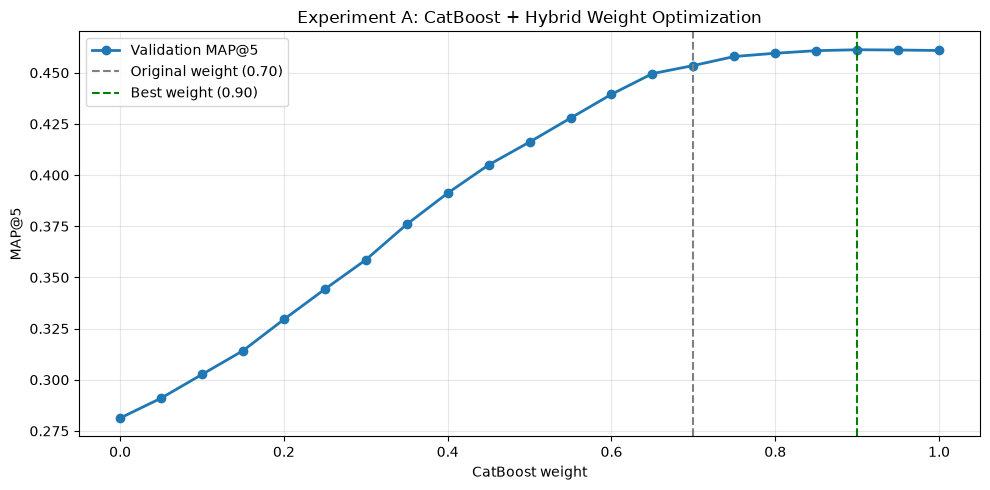


BEST_CATBOOST_WEIGHT = 0.90


In [60]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT A: CATBOOST + HYBRID WEIGHT OPTIMIZATION
# ============================================================

TOP_K = 5
WEIGHTS = np.round(np.arange(0.0, 1.001, 0.05), 2)

# ------------------------------------------------------------
# 1. PREPARE VALIDATION DATA
# ------------------------------------------------------------

assert len(meta_test) == len(X_test_extended) == len(y_test)

val = meta_test[["user_id", "tv_show_id"]].copy()
val = val.reset_index(drop=True)

val["user_id"] = val["user_id"].astype(str)
val["tv_show_id"] = val["tv_show_id"].astype(int)
val["label"] = np.asarray(y_test).ravel()

# Use train-only CatBoost model, not extended_final
val["cb_score"] = extended_model.predict_proba(
    X_test_extended[FEATURES]
)[:, 1]

val["hybrid_score"] = (
    X_test_extended["hybrid_score"].to_numpy()
)

assert val[["cb_score", "hybrid_score"]].notna().all().all()
assert not val.duplicated(["user_id", "tv_show_id"]).any()

print("Validation candidates:", len(val))
print("Validation users:", val["user_id"].nunique())
print("Positive labels:", int(val["label"].sum()))

# ------------------------------------------------------------
# 2. NORMALIZE SCORES PER USER
# Same normalization as final submission
# ------------------------------------------------------------

def normalize_per_user(series):
    values = np.maximum(
        series.to_numpy(dtype=np.float64), 0.0
    )
    maximum = values.max()

    if maximum > 0:
        return values / maximum

    return np.zeros_like(values)

val["cb_norm"] = (
    val.groupby("user_id", sort=False)["cb_score"]
    .transform(normalize_per_user)
)

val["hybrid_norm"] = (
    val.groupby("user_id", sort=False)["hybrid_score"]
    .transform(normalize_per_user)
)

# ------------------------------------------------------------
# 3. MAP@5
# ------------------------------------------------------------

def calculate_map5(df, score_column, k=5):
    ranked = df.sort_values(
        ["user_id", score_column, "tv_show_id"],
        ascending=[True, False, True],
        kind="mergesort"
    )

    relevant = (
        df[df["label"] == 1]
        .groupby("user_id")["tv_show_id"]
        .apply(set)
        .to_dict()
    )

    predictions = (
        ranked.groupby("user_id", sort=False)["tv_show_id"]
        .apply(lambda x: x.head(k).tolist())
        .to_dict()
    )

    scores = []

    for user_id in df["user_id"].unique():
        actual = relevant.get(user_id, set())

        if not actual:
            continue

        hits = 0
        precision_sum = 0.0

        for rank, show_id in enumerate(
            predictions.get(user_id, []), start=1
        ):
            if show_id in actual:
                hits += 1
                precision_sum += hits / rank

        ap = precision_sum / min(len(actual), k)
        scores.append(ap)

    return float(np.mean(scores)) if scores else 0.0

# ------------------------------------------------------------
# 4. GRID SEARCH OVER BLEND WEIGHTS
# ------------------------------------------------------------

results = []

for weight in WEIGHTS:
    val["blend_score"] = (
        weight * val["cb_norm"]
        + (1.0 - weight) * val["hybrid_norm"]
    )

    map5 = calculate_map5(val, "blend_score", TOP_K)

    results.append({
        "catboost_weight": float(weight),
        "hybrid_weight": float(1.0 - weight),
        "MAP@5": map5
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

best_row = results_df.loc[results_df["MAP@5"].idxmax()]
original_row = results_df.loc[
    np.isclose(results_df["catboost_weight"], 0.70)
].iloc[0]

print("\n" + "=" * 55)
print("EXPERIMENT A — CATBOOST / HYBRID BLENDING")
print("=" * 55)

display(
    results_df.sort_values(
        "MAP@5", ascending=False
    ).reset_index(drop=True)
)

print(f"\nBest CatBoost weight: {best_row['catboost_weight']:.2f}")
print(f"Best Hybrid weight:   {best_row['hybrid_weight']:.2f}")
print(f"Best MAP@5:           {best_row['MAP@5']:.6f}")

print(f"\nOriginal 70/30 MAP@5: {original_row['MAP@5']:.6f}")
print(
    f"Improvement: "
    f"{best_row['MAP@5'] - original_row['MAP@5']:+.6f}"
)

# ------------------------------------------------------------
# 6. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    results_df["catboost_weight"],
    results_df["MAP@5"],
    marker="o",
    linewidth=2,
    label="Validation MAP@5"
)

plt.axvline(
    0.70,
    color="gray",
    linestyle="--",
    label="Original weight (0.70)"
)

plt.axvline(
    best_row["catboost_weight"],
    color="green",
    linestyle="--",
    label=f"Best weight ({best_row['catboost_weight']:.2f})"
)

plt.xlabel("CatBoost weight")
plt.ylabel("MAP@5")
plt.title("Experiment A: CatBoost + Hybrid Weight Optimization")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    "experiment_A_blend_weights.csv",
    index=False
)

BEST_CATBOOST_WEIGHT = float(best_row["catboost_weight"])

print(f"\nBEST_CATBOOST_WEIGHT = {BEST_CATBOOST_WEIGHT:.2f}")
